# TARANG: Ring Resonator Example File

In [1]:
# ---- Logging ---- #
from tarang import configure_logging, set_tidy3d_output

configure_logging(level="INFO")  # Show programmer-written TARANG logs
set_tidy3d_output(False)         # Suppress Tidy3D chatter and managed progress bars

# ---- Define Media ---- #
from media import get_medium, get_medium_dispersion

# 1) PECDV SiN Data
Si3N4 = get_medium(
    medium_key = "si3n4",
    wl_range = (1.550 - 0.200, 1.550 + 0.200),
    tolerance = 1e-5
)

# 2) Silica
SiO2 = get_medium(
    medium_key = "sio2",
    wl_range = (1.550 - 0.200, 1.550 + 0.200),
    tolerance = 5e-5
)

2026-09-21 00:47:33,069 - tarang.media.medium_helper - INFO -  Cache MISS for si3n4. Existing entries failed validation: ['wl_range_out_of_bounds']. Fitting data...
2026-09-21 00:47:33,071 - tarang.media.medium_helper - INFO -  Running local fitter for si3n4 (up to 10 poles)...


2026-09-21 00:47:35,852 - tarang.media.medium_helper - INFO -  si3n4 fit complete! RMS Error: 2.66e-15
2026-09-21 00:47:35,853 - tarang.media.medium_helper - INFO -  si3n4 cached new fit to Luke_Si3N4_e9174844.json and updated manifest.

2026-09-21 00:47:35,856 - tarang.media.medium_helper - INFO -  Cache MISS for sio2. Existing entries failed validation: ['wl_range_out_of_bounds']. Fitting data...
2026-09-21 00:47:35,857 - tarang.media.medium_helper - INFO -  Running local fitter for sio2 (up to 10 poles)...


2026-09-21 00:47:38,236 - tarang.media.medium_helper - INFO -  sio2 fit complete! RMS Error: 1.32e-05
2026-09-21 00:47:38,237 - tarang.media.medium_helper - INFO -  sio2 cached new fit to Nyakuchena_fusedSilica_65d24012.json and updated manifest.



## Ring Resonator + Bus Waveguide: Example Geometry

2026-09-21 00:48:07,592 - tarang.media.medium_helper - INFO -  Bypassing file system for air. Returning dispersionless vacuum medium (n=1.0)...
2026-09-21 00:48:07,592 - tarang.media.medium_helper - INFO -  Bypassing file system for air. Returning dispersionless vacuum medium (n=1.0)...
2026-09-21 00:48:07,595 - tarang.media.medium_helper - INFO -  Bypassing file system for air. Returning dispersionless vacuum medium (n=1.0)...
2026-09-21 00:48:07,595 - tarang.media.medium_helper - INFO -  Bypassing file system for air. Returning dispersionless vacuum medium (n=1.0)...
2026-09-21 00:48:07,595 - tarang.media.medium_helper - INFO -  Bypassing file system for air. Returning dispersionless vacuum medium (n=1.0)...
2026-09-21 00:48:07,940 - tarang.geometries.half_ring_resonator - INFO - [Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-40.65, Z=0.175
2026-09-21 00:48:08,503 - tarang.utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: examp

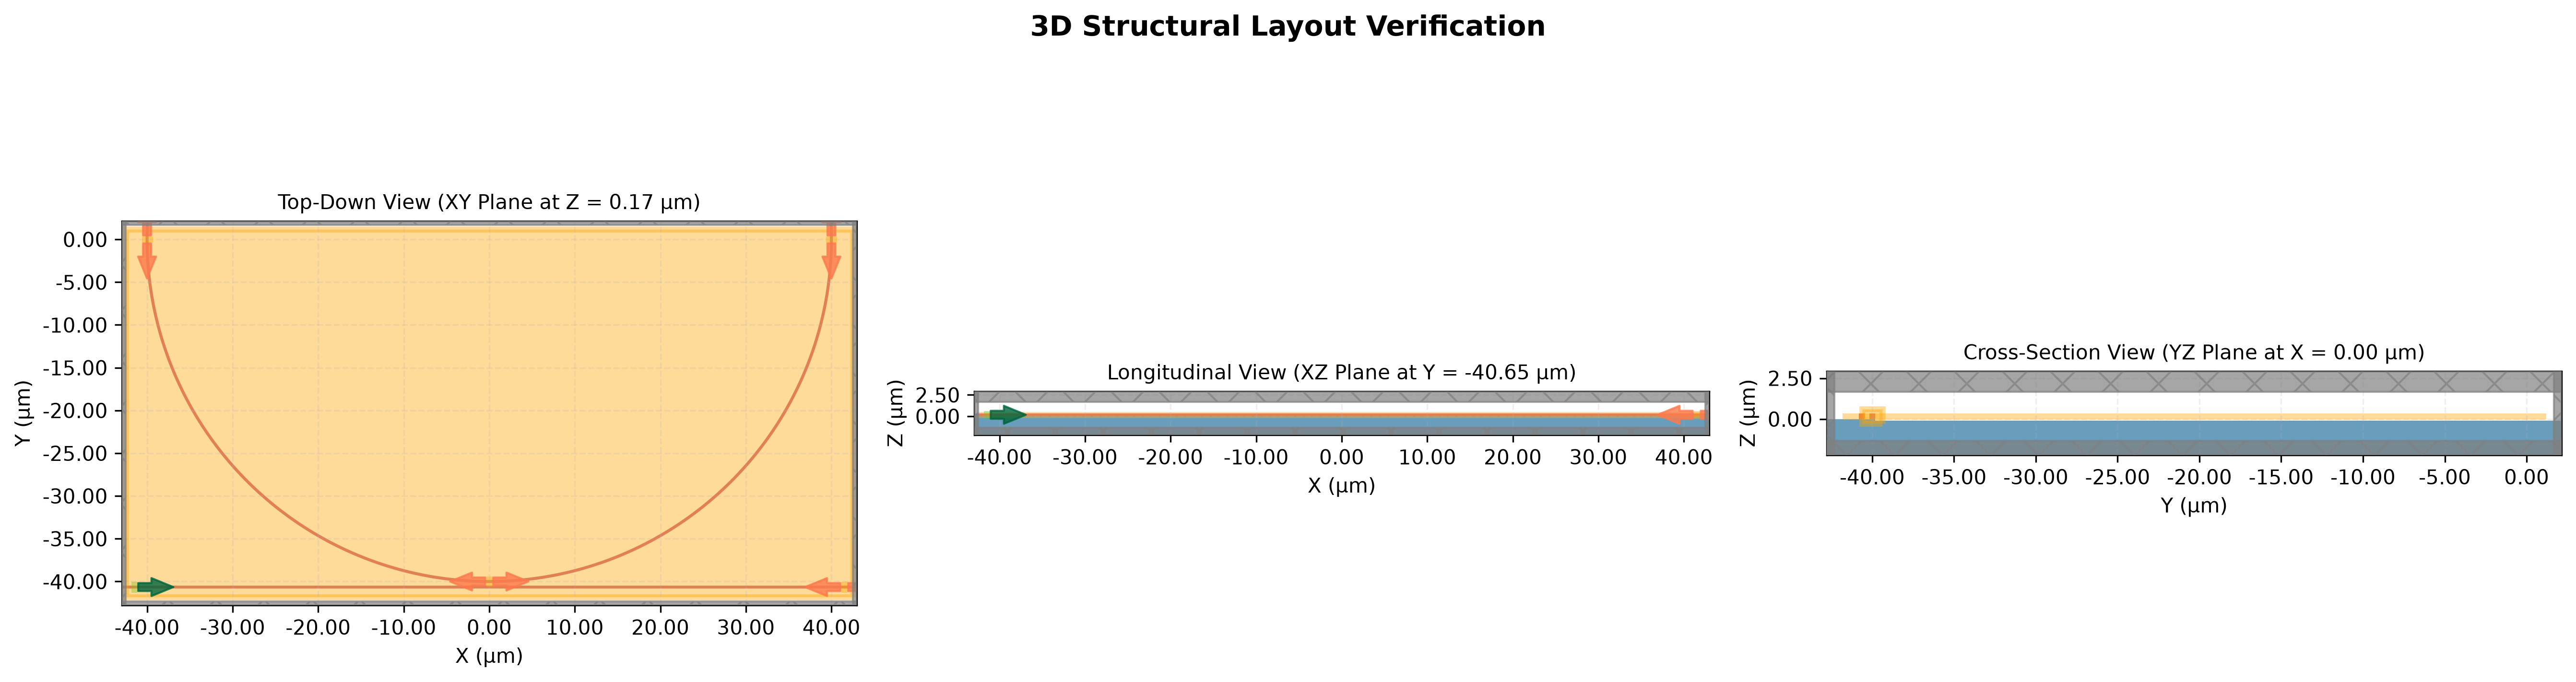

In [ ]:
# ---- Half Ring Resonator ---- #
from ringResonator import halfringResonator
from geometries import half_ring_resonator

example_halfring_resonator = half_ring_resonator.get_active_simulation(
    radius = 40.0,
    gap = 0.300,

    wg_width=0.350,
    wg_height=0.350,

    core_medium = Si3N4,
    substrate_medium = SiO2,

    wavelength0=1.550,

    substrate_height=4.0,
)

from utilities.sim_plotter import display_3d

display_3d(
    device = example_halfring_resonator,
    output_path = "example_results/ring_resonator/halfring_resonator/example_geometry.png",
    save = True,
    coordinates = half_ring_resonator.get_optimal_plot_coords(example_halfring_resonator.sim)
)

2026-09-21 00:48:17,987 - tarang.geometries.full_ring_resonator - INFO - [Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-100.85, Z=0.175
2026-09-21 00:48:18,570 - tarang.utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/fullring_resonator/example_geometry.png


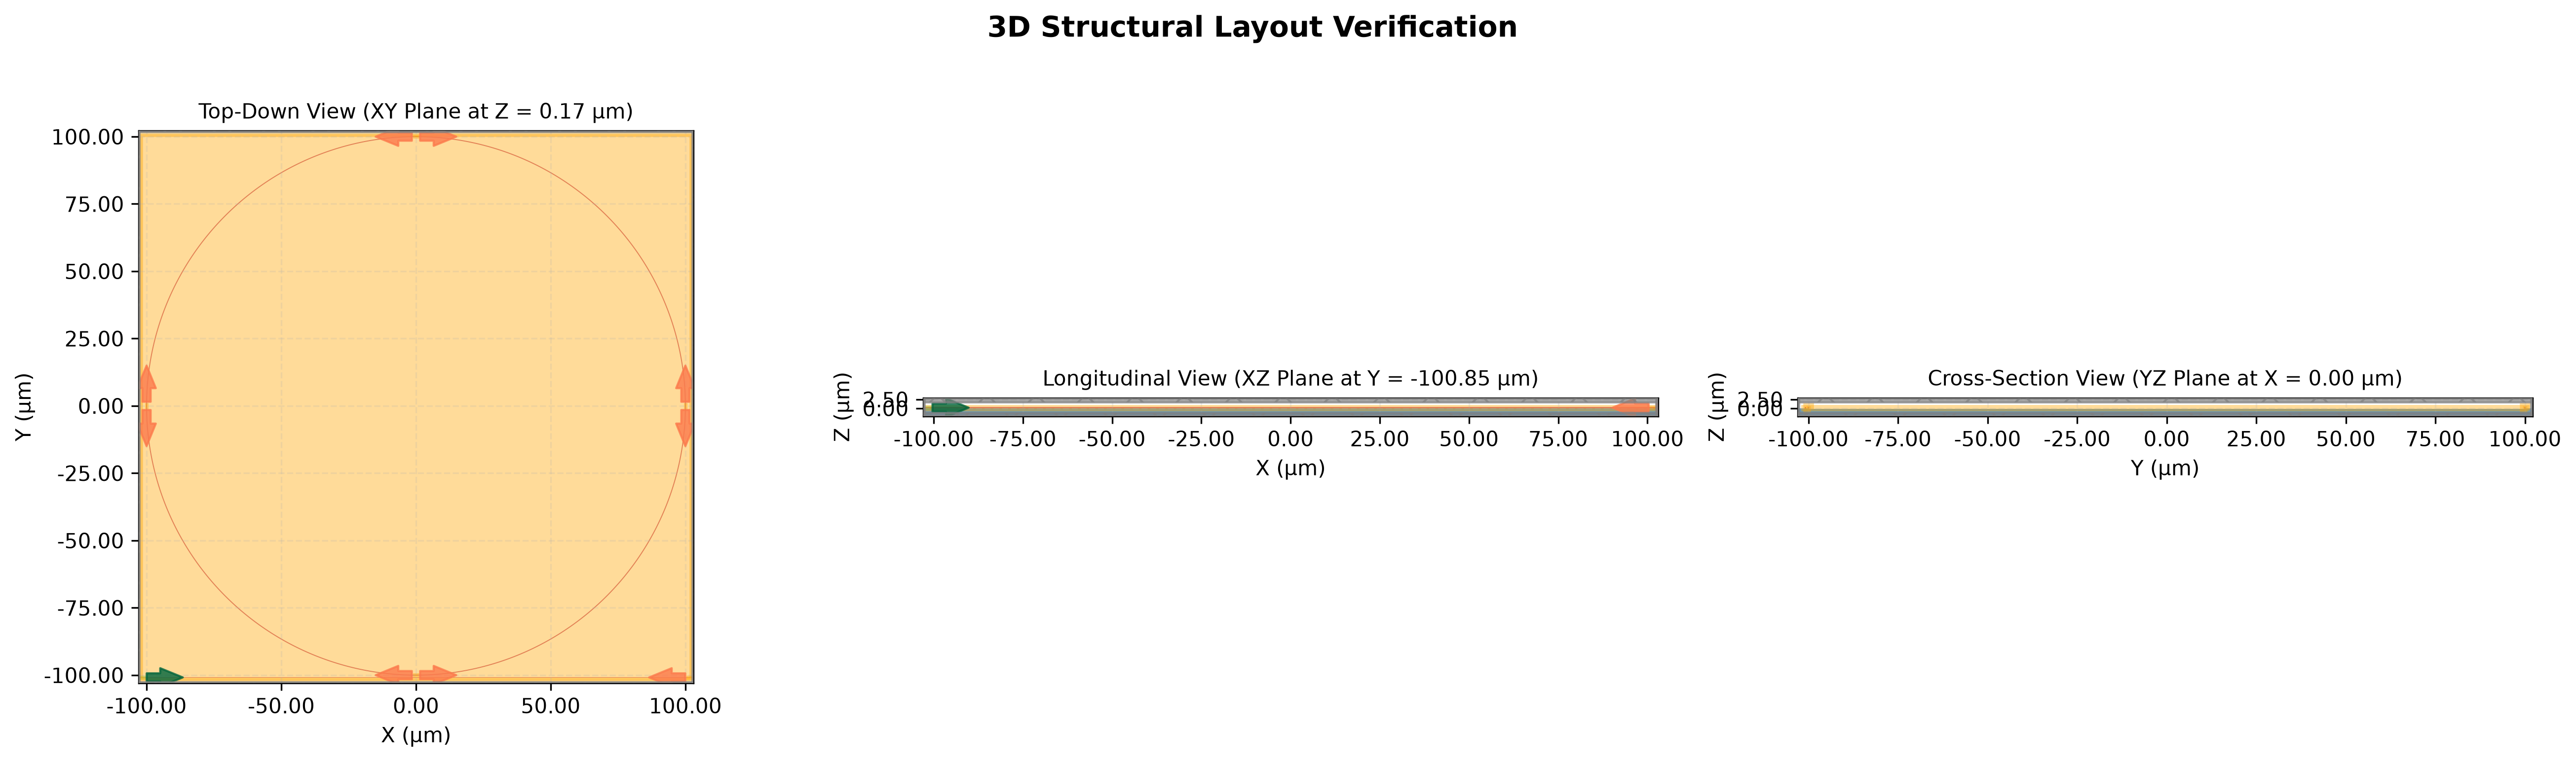

In [ ]:
# ---- Full Ring Resonator ---- #
from ringResonator import ringResonator
from geometries import full_ring_resonator

example_ring_resonator = full_ring_resonator.get_active_simulation(
    radius = 100.0,
    gap = 0.500,

    wg_width=0.350,
    wg_height=0.350,

    core_medium = Si3N4,
    substrate_medium = SiO2,

    wavelength0=1.550,

    substrate_height=2.0,
)

from utilities.sim_plotter import display_3d

display_3d(
    device = example_ring_resonator,
    output_path = "example_results/ring_resonator/fullring_resonator/example_geometry.png",
    save = True,
    coordinates = full_ring_resonator.get_optimal_plot_coords(example_ring_resonator.sim)
)

/tmp/ipykernel_113230/631709614.py:6: UserWarning: The supplied partial-ring geometry ends inside the simulation domain. Check ring-port reflections and span convergence; its endpoints are not matched absorbers.
  example_60_ring_resonator = partial_ring_resonator.get_active_simulation(
2026-09-21 00:48:22,328 - tarang.geometries.partial_ring_resonator - INFO - [Visualizer] Locking All-Pass slice view onto coupling domain center: X=0.000, Y=-37.922, Z=0.400
2026-09-21 00:48:22,846 - tarang.utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/partial_ring_resonator/example_geometry_60.png


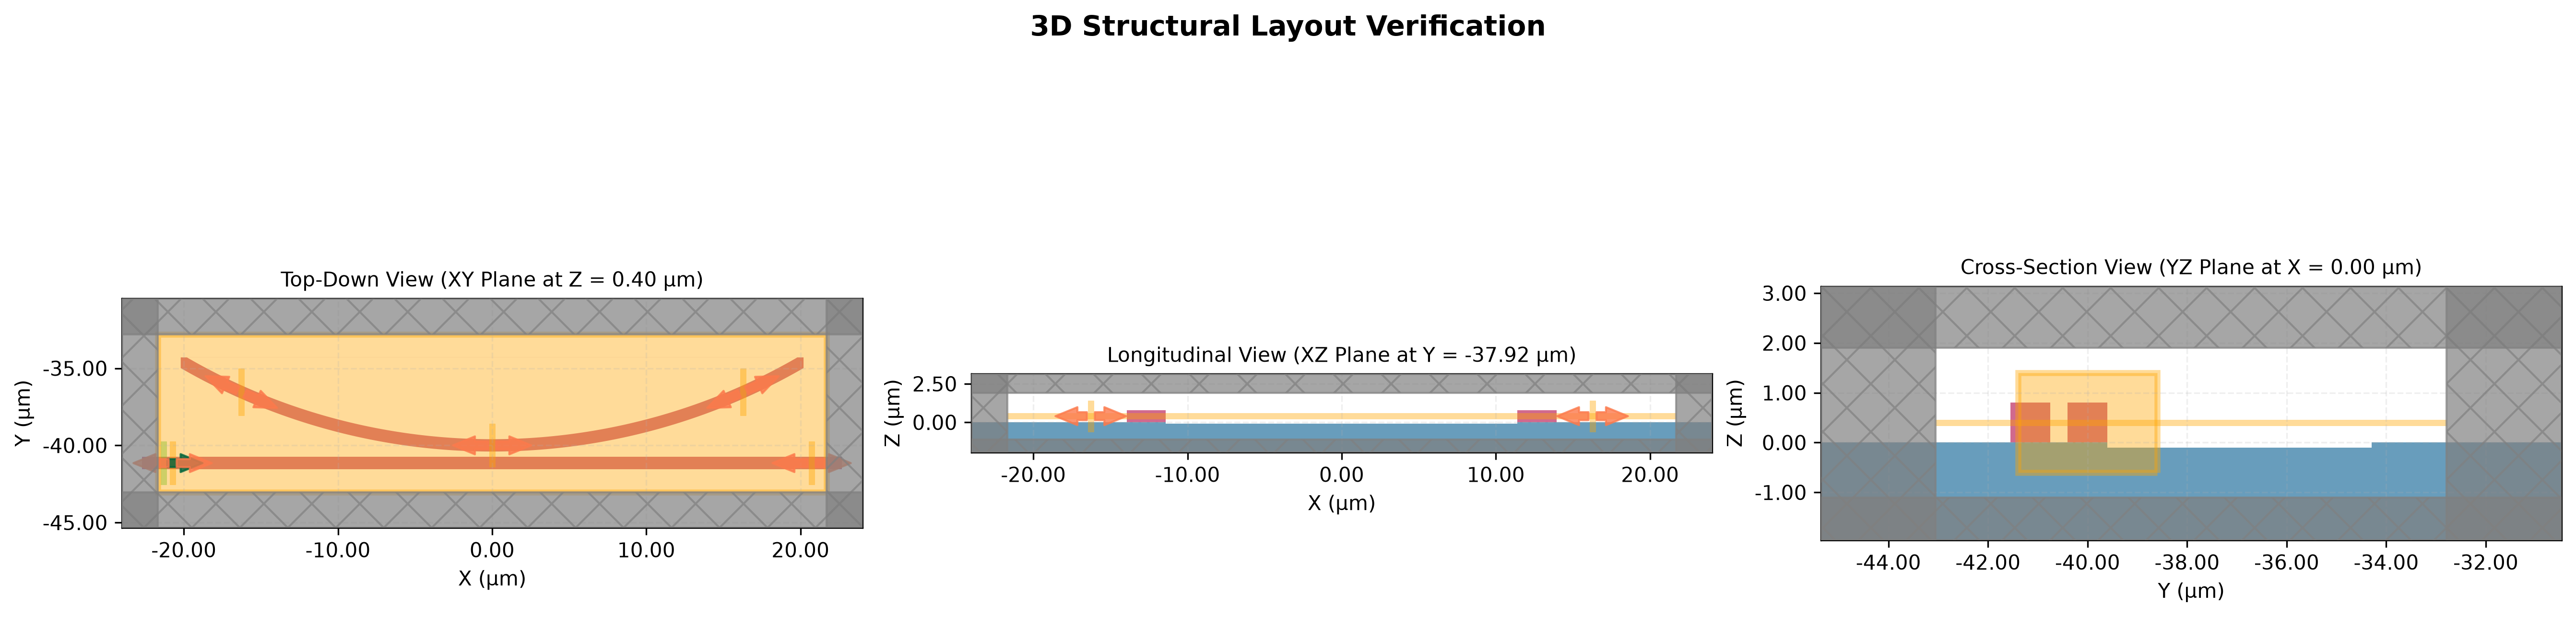

In [ ]:
# ---- Partial Ring Resonator ---- #
"""
One would find this geometry particularly useful for smaller
FDTD runs.
"""
from geometries import partial_ring_resonator, half_ring_resonator
import numpy as np

# Define a section that considers 30 degrees of the ring
example_60_ring_resonator = partial_ring_resonator.get_active_simulation(
    radius = 40.0,
    gap = 0.350,
    wg_width = 0.800,
    wg_height = 0.800,
    core_medium = Si3N4,
    substrate_medium = SiO2,
    wavelength0 = 1.550,
    span_angle_rad = np.radians(60)
)

from utilities.sim_plotter import display_3d

display_3d(
    device = example_60_ring_resonator,
    output_path = "example_results/ring_resonator/partial_ring_resonator/example_geometry_60.png",
    save = True,
    coordinates = partial_ring_resonator.get_optimal_plot_coords(example_60_ring_resonator.sim)
)

## Ring Resonator + Bus Waveguide: Converting geometry types
(Half-Ring -> Full-Ring)<br>
(Full-Ring -> Half-Ring)<br>
(Partial Rings -> Half-Rings,Full-Rings)

2026-09-21 00:50:46,067 - tarang.geometries.full_ring_resonator - INFO - [Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-100.85, Z=0.175
2026-09-21 00:50:46,583 - tarang.utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/converted2fullring_resonator/original_geometry.png


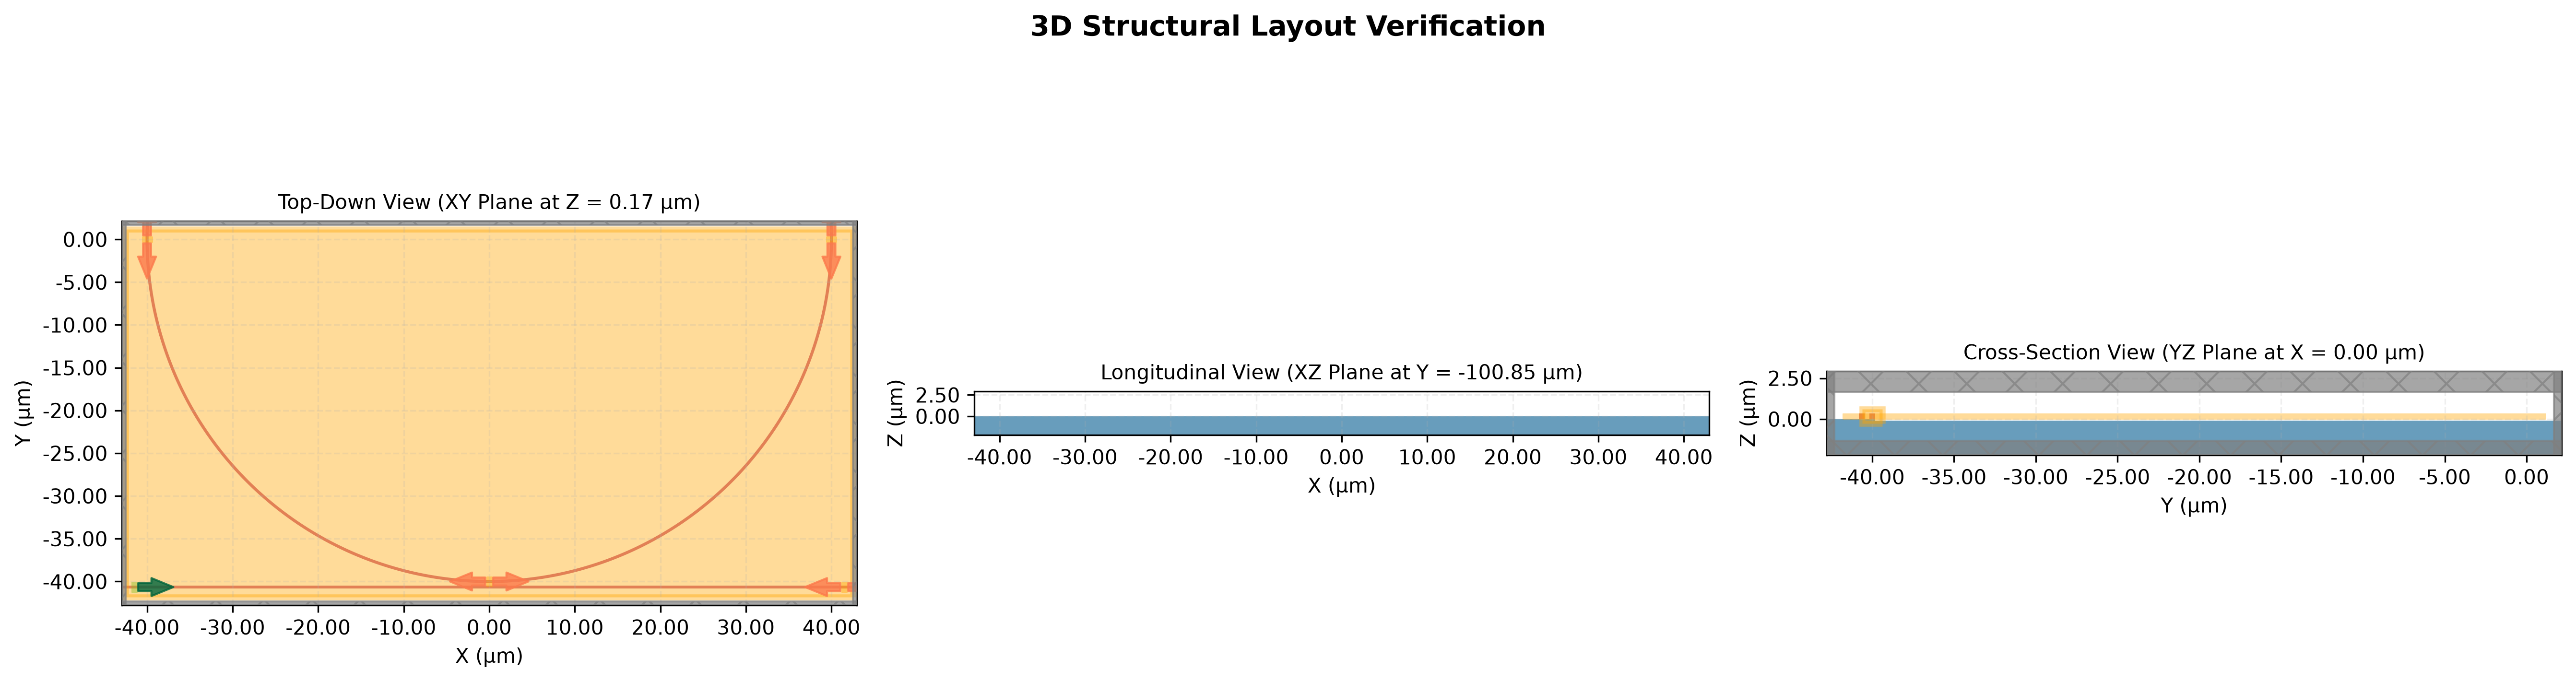

2026-09-21 00:50:46,916 - tarang.geometries.full_ring_resonator - INFO - [Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-100.85, Z=0.175
2026-09-21 00:50:47,444 - tarang.utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/converted2fullring_resonator/converted_geometry.png


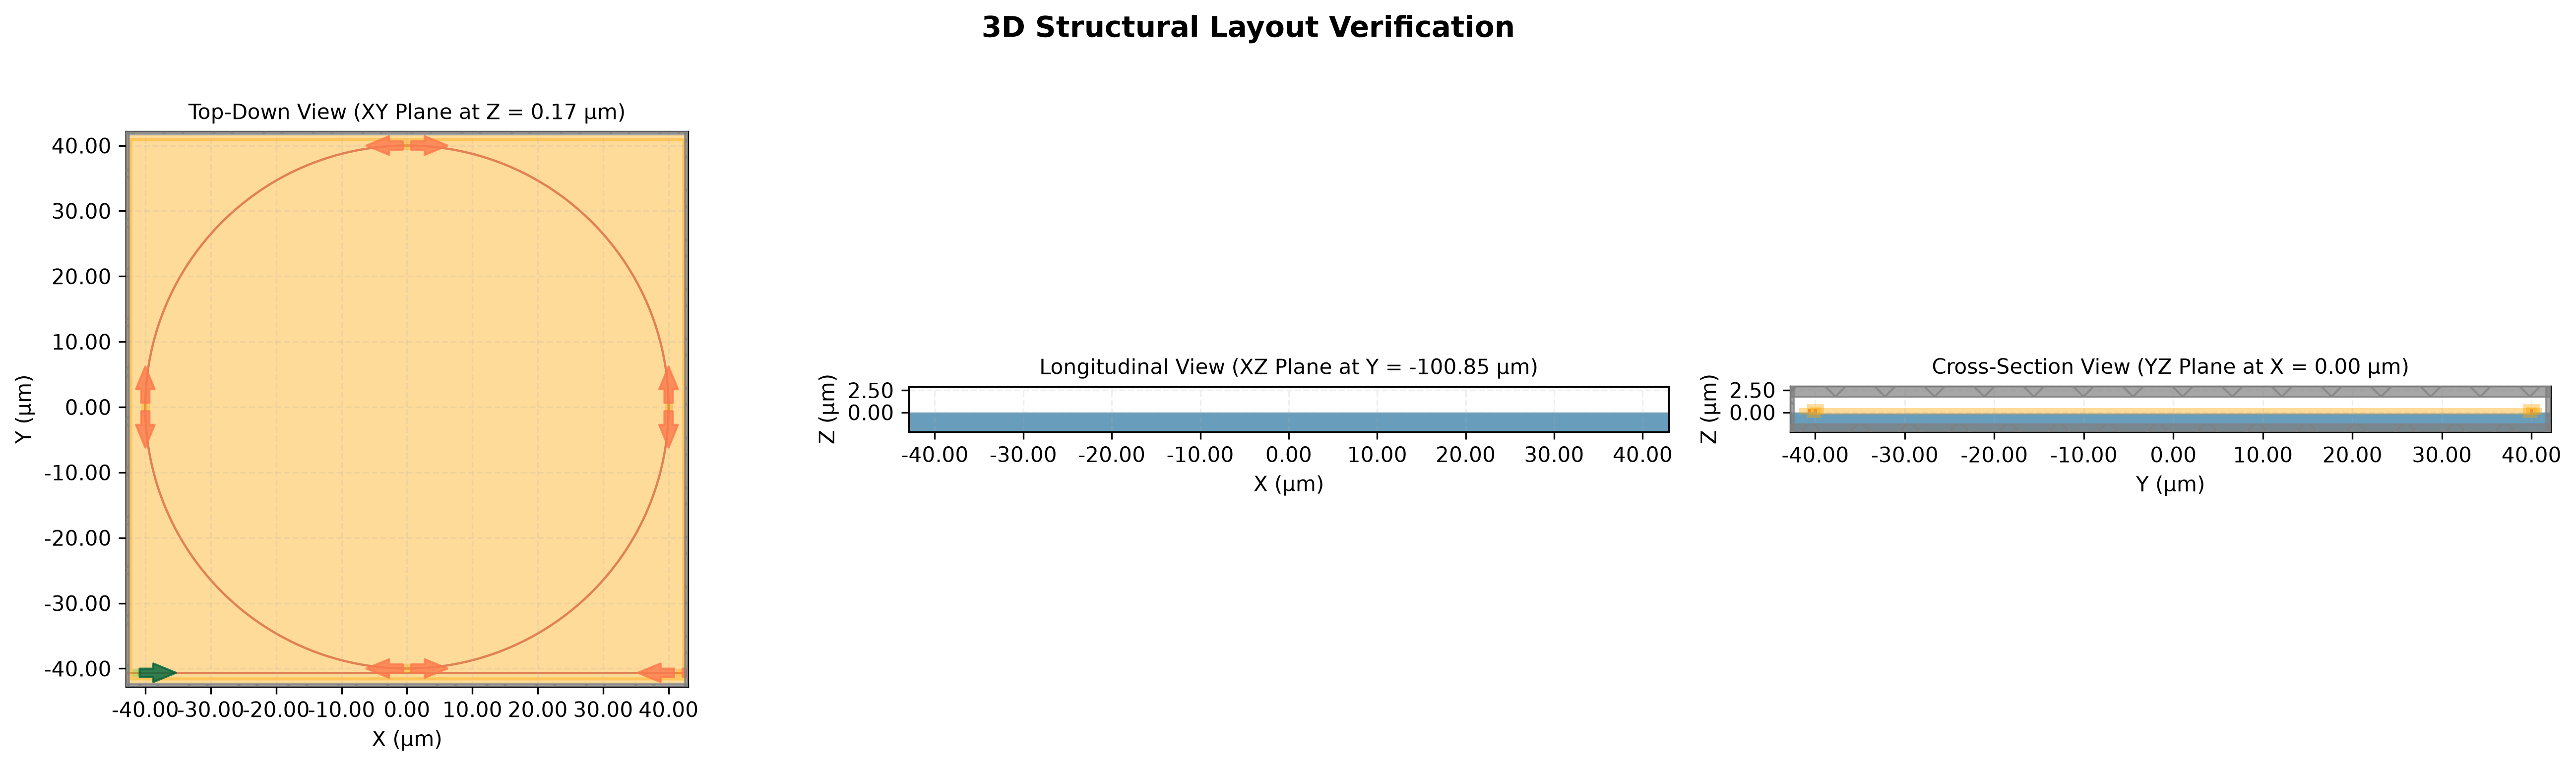

In [5]:
# ---- Converting Ring Types -- Half-ring to Full-ring ---- #

# Re-display the half-ring resonator defined two cells ago
display_3d(
    device = example_halfring_resonator,
    output_path = "example_results/ring_resonator/converted2fullring_resonator/original_geometry.png",
    save = True,
    coordinates = full_ring_resonator.get_optimal_plot_coords(example_ring_resonator.sim)
)

# Convert to full-ring geometry.
converted_ring_resonator = example_halfring_resonator.to_full_ring(active = True)

display_3d(
    device = converted_ring_resonator,
    output_path = "example_results/ring_resonator/converted2fullring_resonator/converted_geometry.png",
    save = True,
    coordinates = full_ring_resonator.get_optimal_plot_coords(example_ring_resonator.sim)
)

2026-09-21 00:50:49,862 - tarang.geometries.full_ring_resonator - INFO - [Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-100.85, Z=0.175
2026-09-21 00:50:50,415 - tarang.utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/converted2halfring_resonator/original_geometry.png


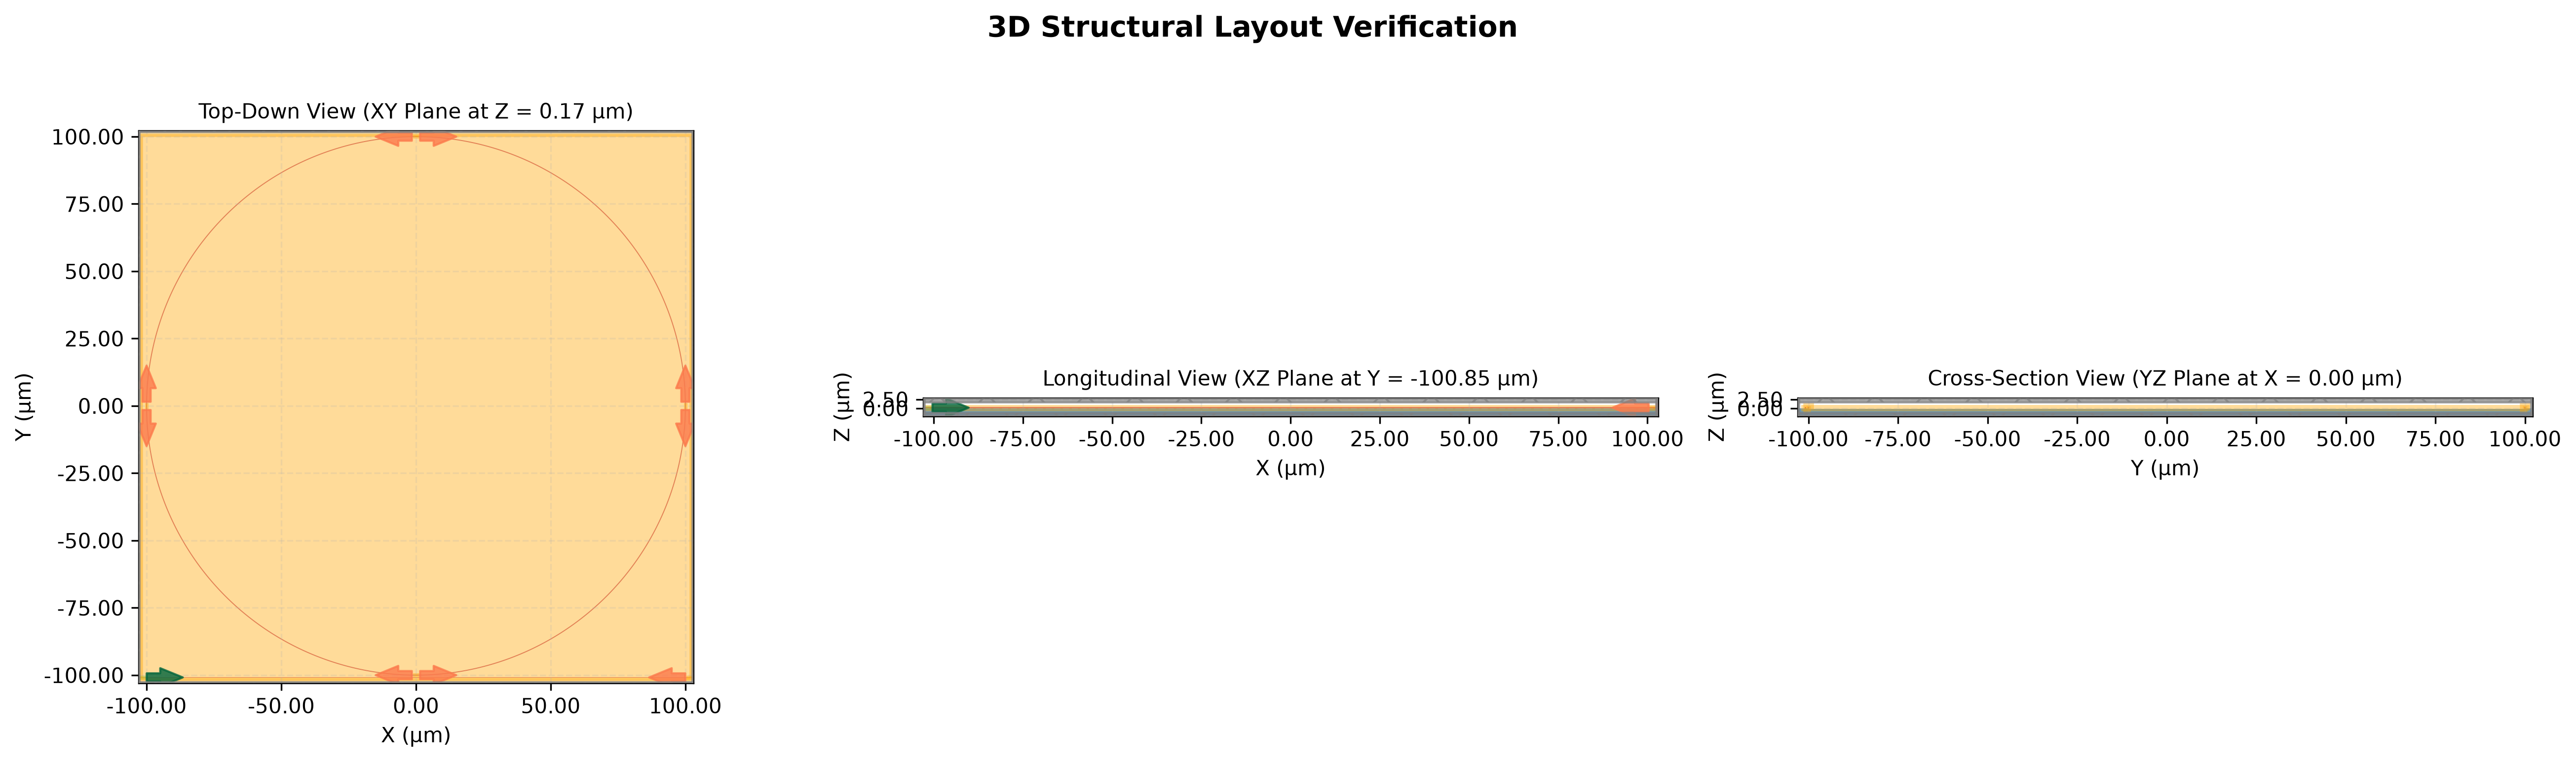

2026-09-21 00:50:50,717 - tarang.geometries.full_ring_resonator - INFO - [Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-100.85, Z=0.175
2026-09-21 00:50:51,171 - tarang.utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/converted2halfring_resonator/converted_geometry.png


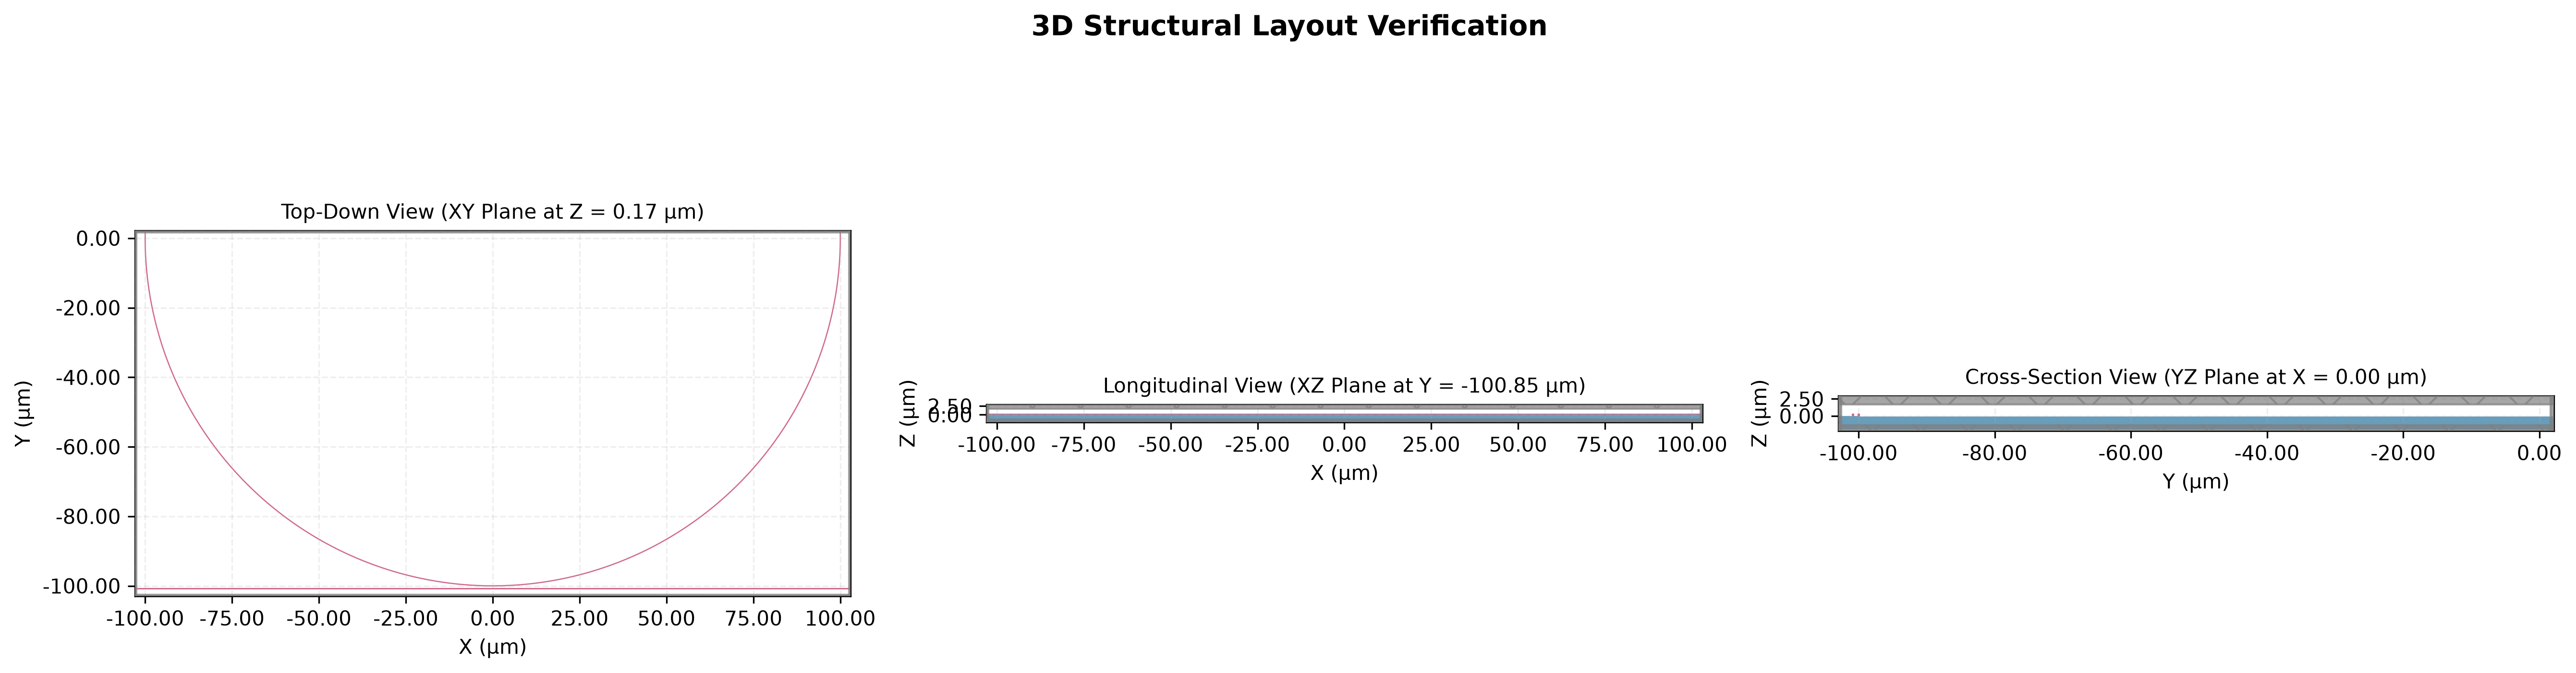

In [6]:
# ---- Converting Ring Types -- Full-ring to Half-ring ---- #

# Re-display the half-ring resonator defined two cells ago
display_3d(
    device = example_ring_resonator,
    output_path = "example_results/ring_resonator/converted2halfring_resonator/original_geometry.png",
    save = True,
    coordinates = full_ring_resonator.get_optimal_plot_coords(example_ring_resonator.sim)
)

# Convert to full-ring passive geometry
converted_halfring_resonator = example_ring_resonator.to_half_ring(
    active = False # Generate a passive simulation, if you'd like to
)

display_3d(
    device = converted_halfring_resonator,
    output_path = "example_results/ring_resonator/converted2halfring_resonator/converted_geometry.png",
    save = True,
    coordinates = full_ring_resonator.get_optimal_plot_coords(example_ring_resonator.sim)
)

2026-09-21 00:50:54,300 - tarang.geometries.half_ring_resonator - INFO - [Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-41.15, Z=0.4
2026-09-21 00:50:54,776 - tarang.utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/converted_partial_ring/converted_half_ring.png


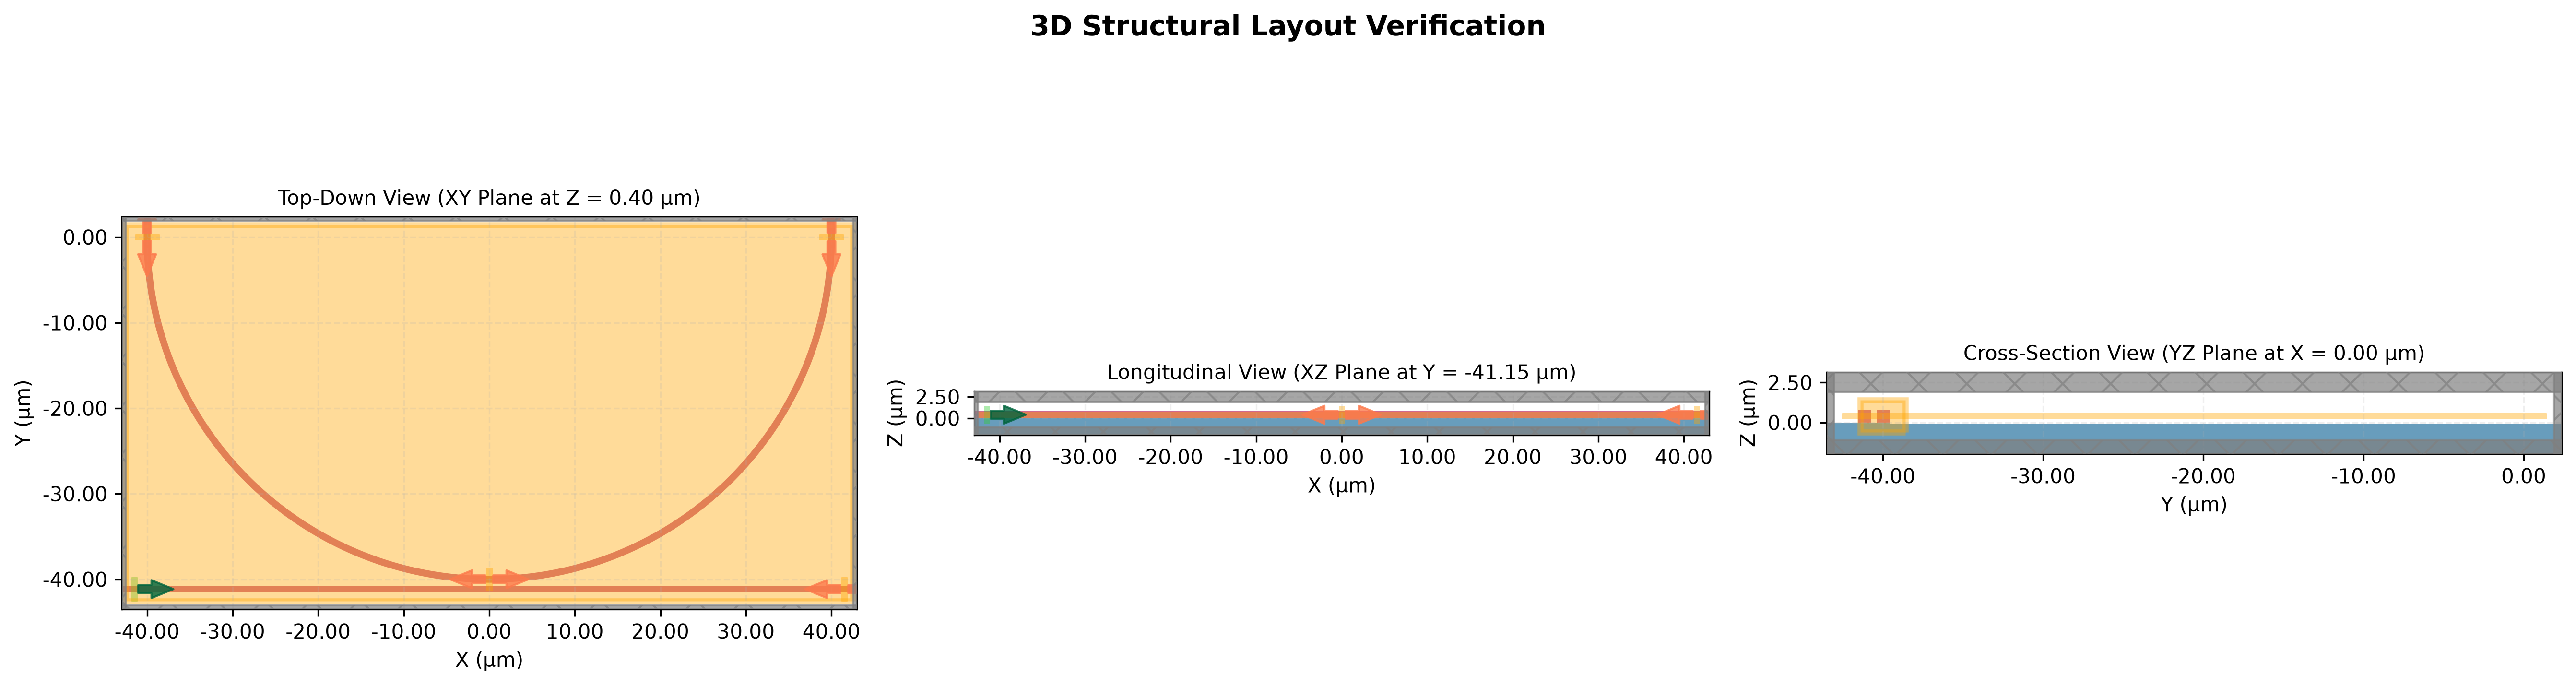

2026-09-21 00:50:55,260 - tarang.geometries.full_ring_resonator - INFO - [Visualizer] Locking All-Pass slice view onto coupling center: X=0.0, Y=-41.15, Z=0.4
2026-09-21 00:50:55,800 - tarang.utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/converted_partial_ring/converted_full_ring.png


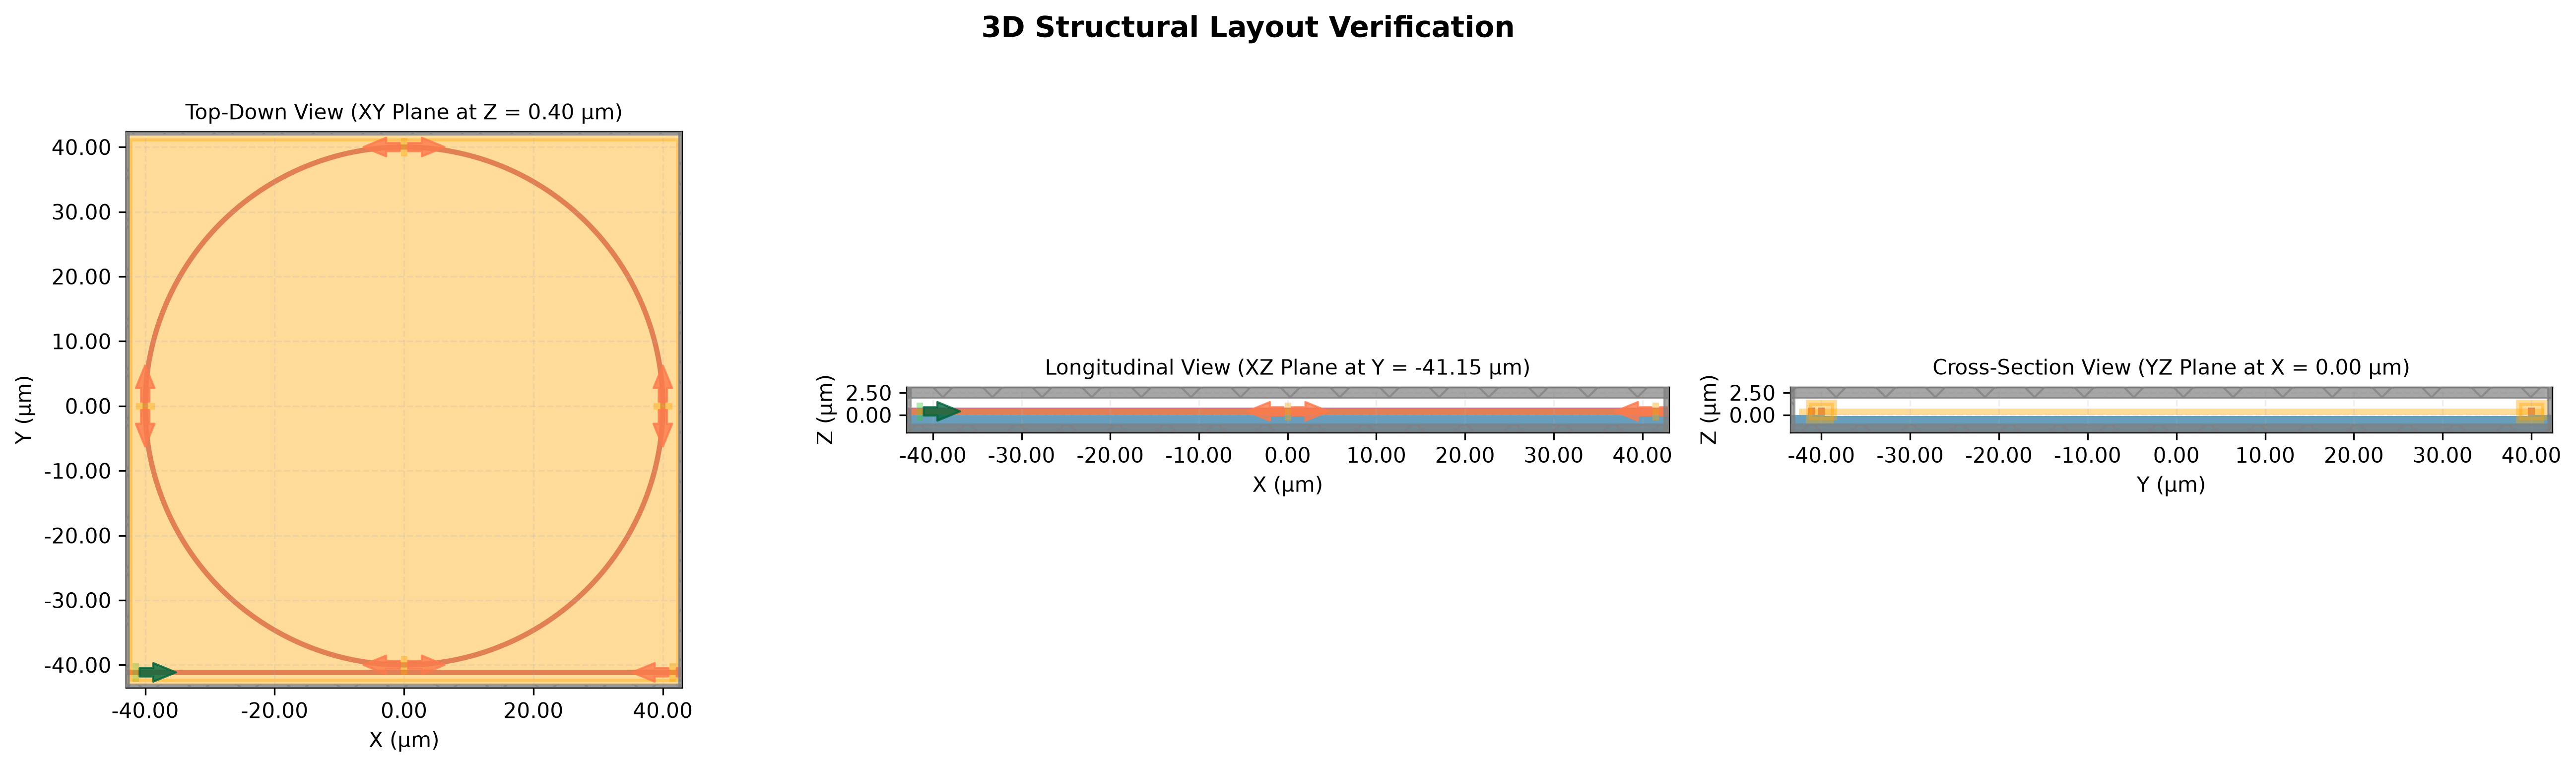

In [7]:
# ---- Converting Ring Types -- Partial-rings to Half and Full rings ---- #
from geometries import half_ring_resonator, full_ring_resonator
# Convert to a half ring
converted_half_ring = example_60_ring_resonator.to_half_ring(active = True)

display_3d(
    device = converted_half_ring,
    output_path = "example_results/ring_resonator/converted_partial_ring/converted_half_ring.png",
    save = True,
    coordinates = half_ring_resonator.get_optimal_plot_coords(converted_half_ring.sim)
)

# Convert to a full ring
converted_full_ring = example_60_ring_resonator.to_full_ring(active = True)

display_3d(
    device = converted_full_ring,
    output_path = "example_results/ring_resonator/converted_partial_ring/converted_full_ring.png",
    save = True,
    coordinates = full_ring_resonator.get_optimal_plot_coords(converted_full_ring.sim)
)

## Ring Resonator Arcs (Bend Geometries) : Example Geometries

2026-09-21 00:51:22,875 - tarang.geometries.resonator_arc - INFO - [Visualizer] Locking Bend slice view onto core center: X=0.0, Y=0.0, Z=0.4
2026-09-21 00:51:23,352 - tarang.utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/resonator_arcs/example_90deg_arc.png


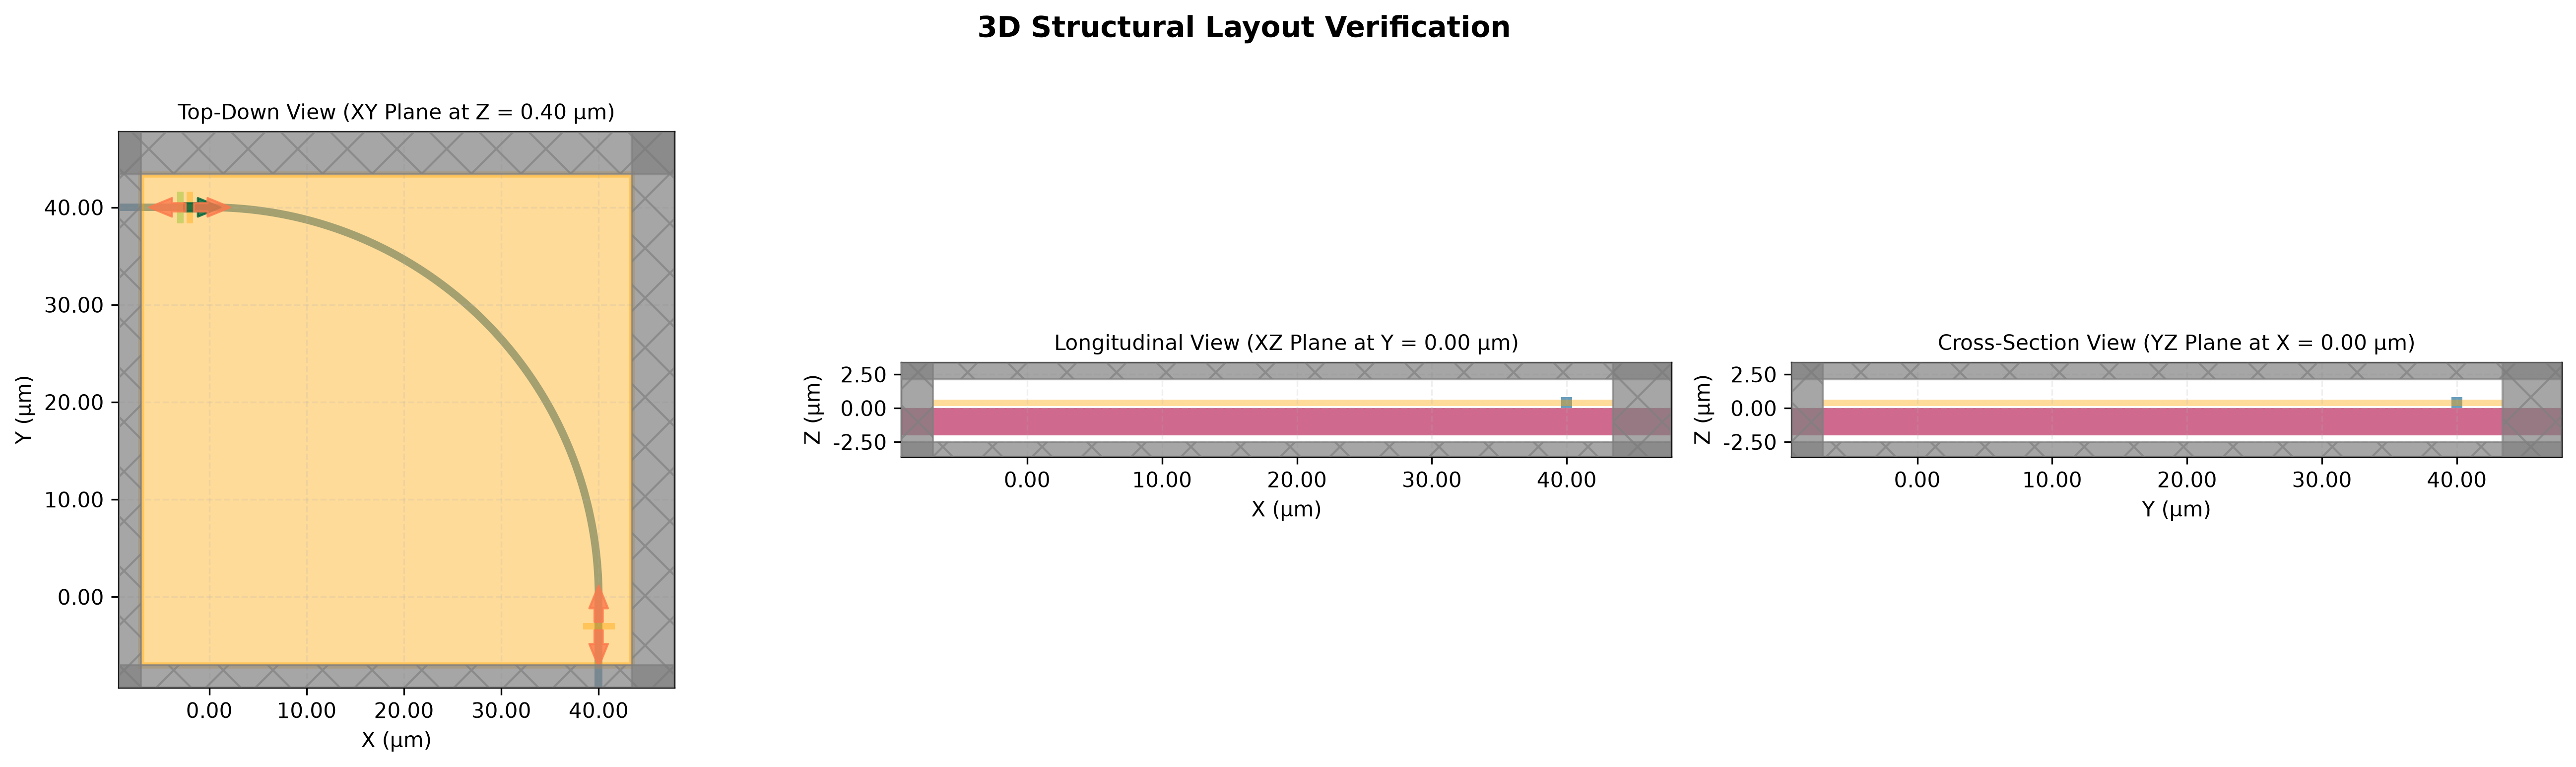

In [ ]:
# ---- Generate Ring Resonator Arcs ---- #
from ringResonator.resonator_arc import resonatorArc
from geometries import resonator_arc as geom_arc
from utilities.sim_plotter import display_2d, display_3d

# -- Example 90 Degrees -- #
example_90_arc = geom_arc.get_active_simulation(
    wavelength0 = 1.550,

    radius = 40.0,

    wg_width = 0.800,
    wg_height = 0.800,

    core_medium = Si3N4,
    substrate_medium = SiO2,

    bend_angle_deg = 90.0,
    
    num_absorber_layers = 60
)

display_3d(
    device = example_90_arc,
    output_path = "example_results/ring_resonator/resonator_arcs/example_90deg_arc.png",
    save = True,
    coordinates = geom_arc.get_optimal_plot_coords(example_90_arc.sim)
)

2026-09-21 00:51:27,342 - tarang.geometries.resonator_arc - INFO - [Visualizer] Locking Bend slice view onto core center: X=0.0, Y=0.0, Z=0.4
2026-09-21 00:51:27,796 - tarang.utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/resonator_arcs/example_180deg_arc.png


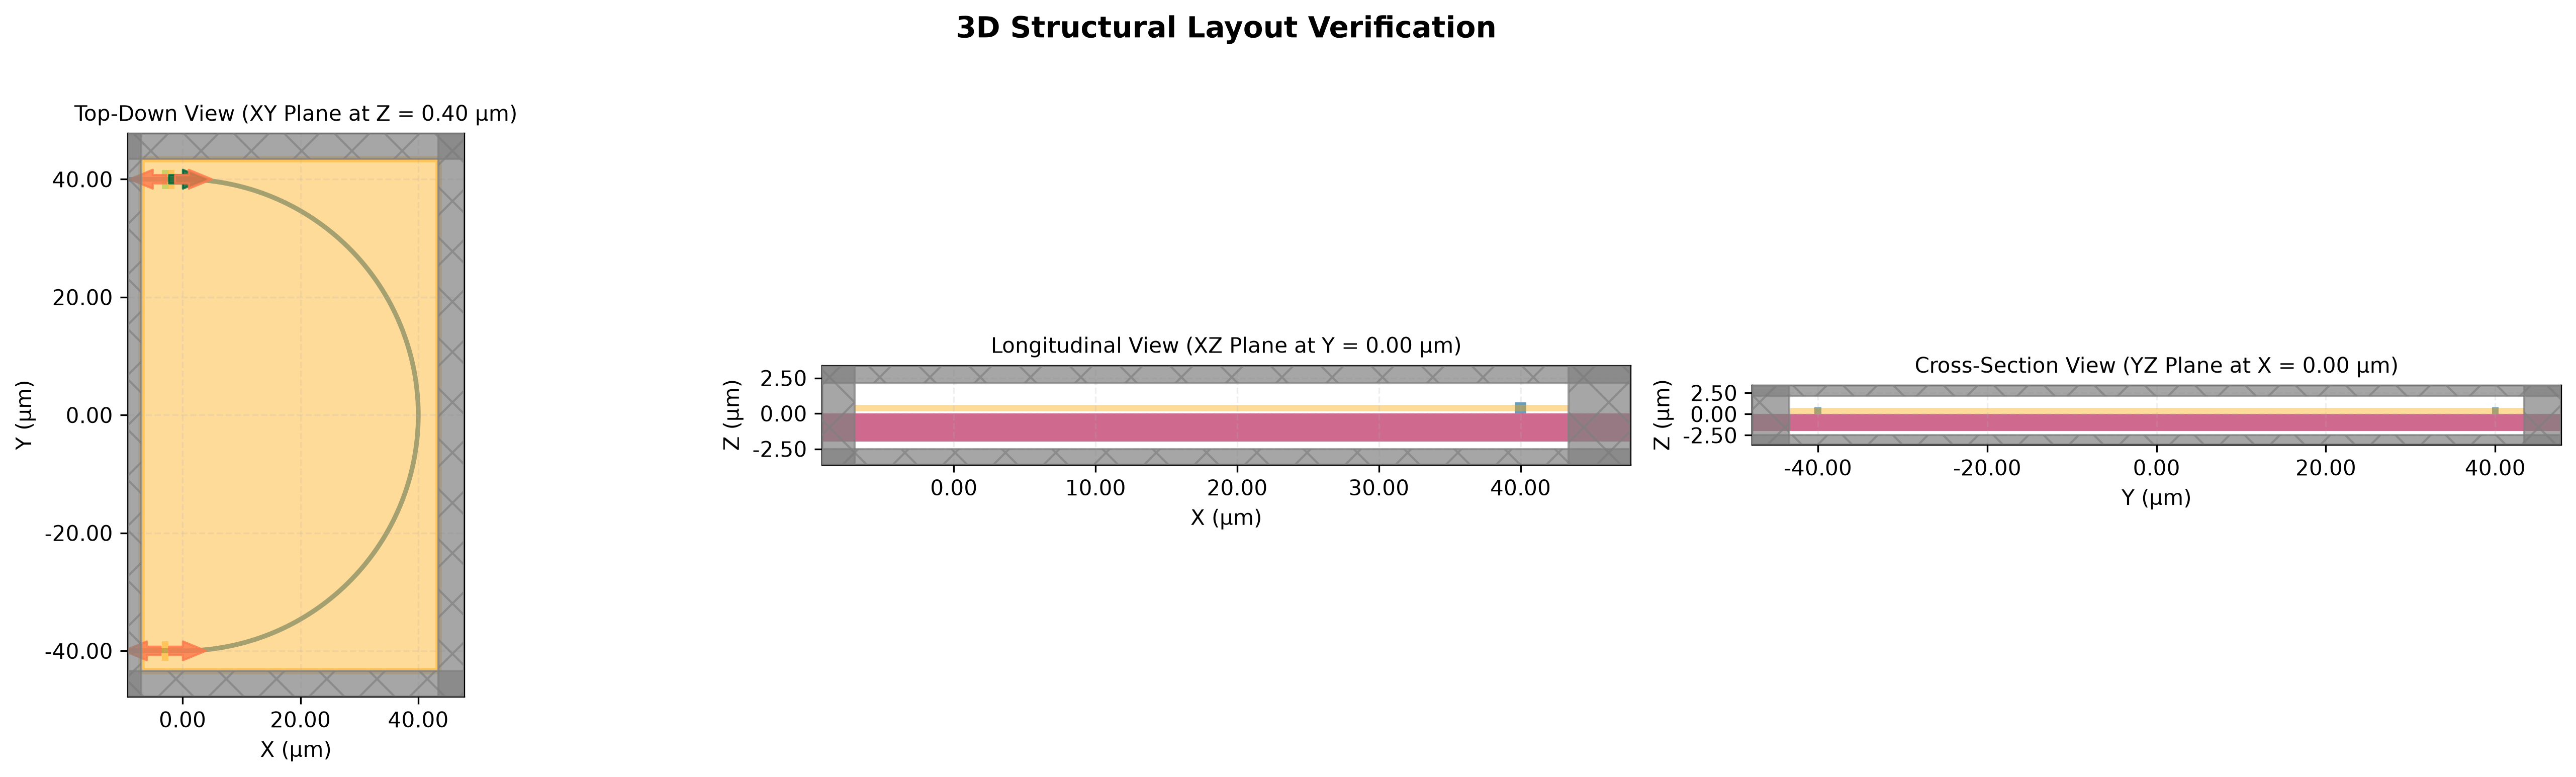

In [ ]:
from ringResonator.resonator_arc import resonatorArc
from geometries import resonator_arc as geom_arc
from utilities.sim_plotter import display_2d, display_3d

# -- Example 180 Degrees -- #
example_180_arc = geom_arc.get_active_simulation(
    wavelength0 = 1.550,

    radius = 40.0,

    wg_width = 0.800,
    wg_height = 0.800,

    core_medium = Si3N4,
    substrate_medium = SiO2,

    bend_angle_deg = 180.0,
    
    num_absorber_layers = 60
)

display_3d(
    device = example_180_arc,
    output_path = "example_results/ring_resonator/resonator_arcs/example_180deg_arc.png",
    save = True,
    coordinates = geom_arc.get_optimal_plot_coords(example_180_arc.sim)
)

2026-09-21 00:52:40,480 - tarang.geometries.resonator_arc - INFO - [Visualizer] Locking Bend slice view onto core center: X=0.0, Y=0.0, Z=0.4
2026-09-21 00:52:41,030 - tarang.utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/ring_resonator/resonator_arcs/example_30deg_arc.png


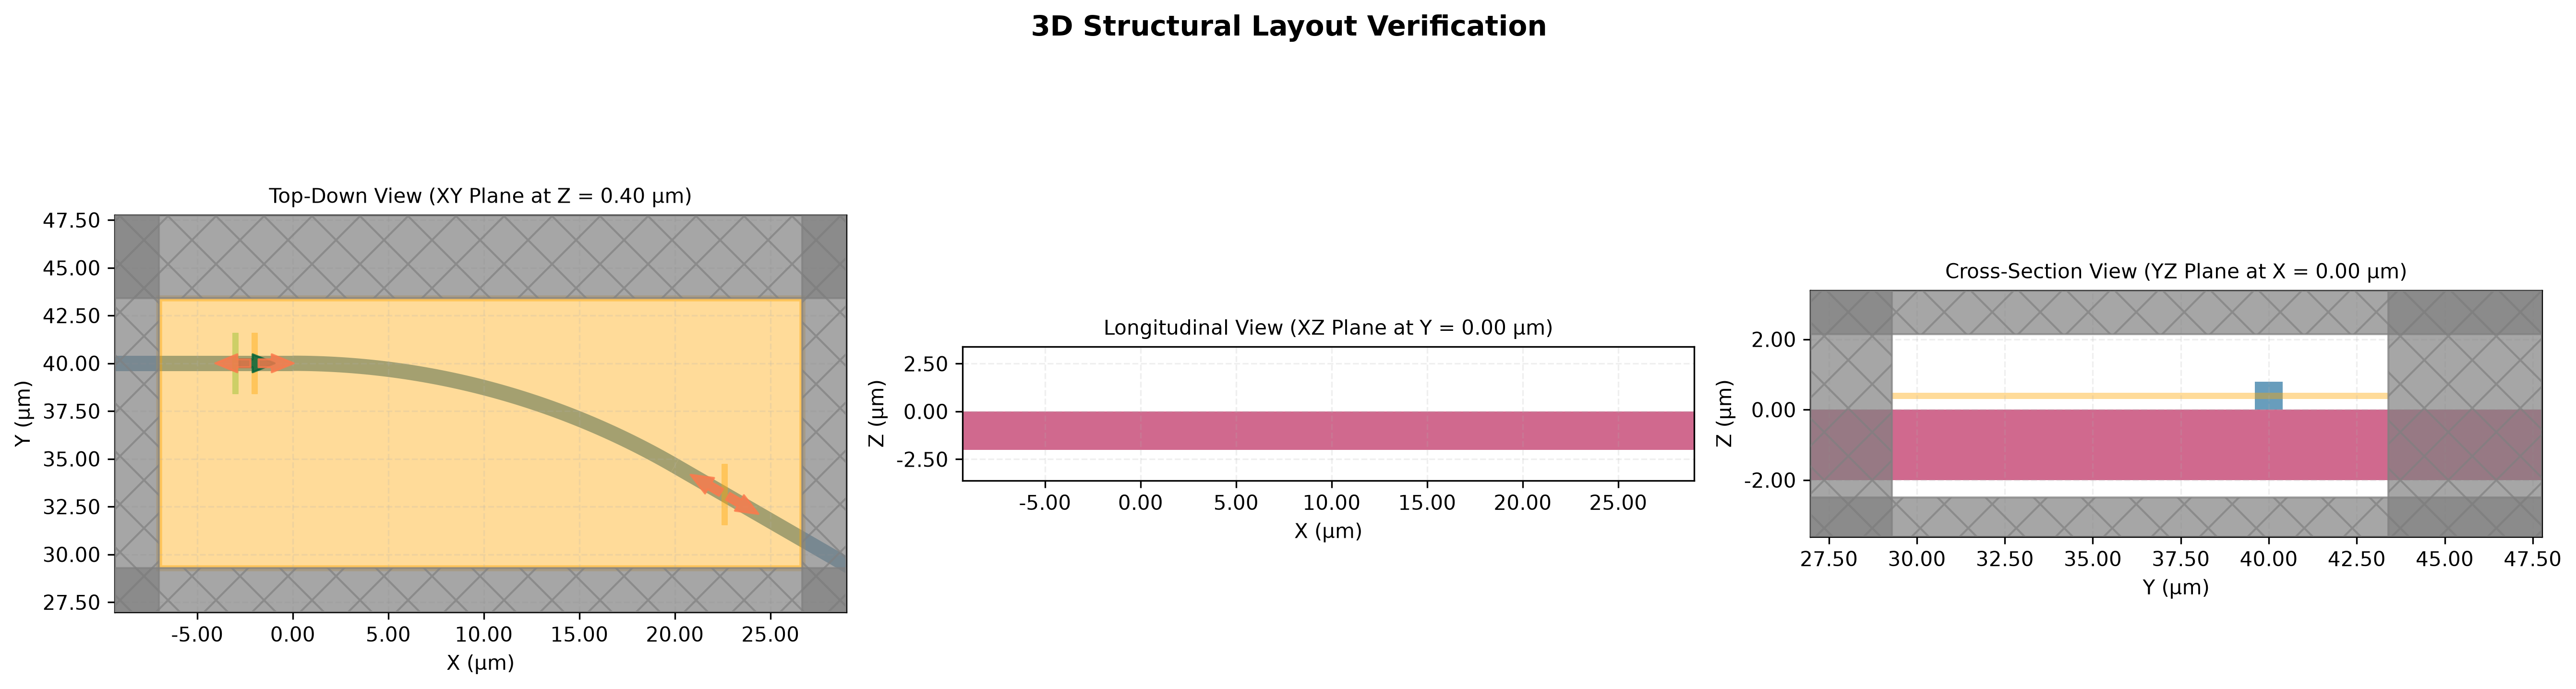

In [13]:
from ringResonator.resonator_arc import resonatorArc
from geometries import resonator_arc as geom_arc
from utilities.sim_plotter import display_2d, display_3d

# -- Example Theta Degrees Arc -- #
theta = 30 # Degrees

example_theta_arc = geom_arc.get_active_simulation(
    wavelength0 = 1.550,
    radius = 40.0,
    wg_width = 0.800,
    wg_height = 0.800,
    core_medium = Si3N4,
    substrate_medium = SiO2,
    bend_angle_deg = theta,
    num_absorber_layers = 60
)

display_3d(
    device = example_theta_arc,
    output_path = f"example_results/ring_resonator/resonator_arcs/example_{int(theta)}deg_arc.png",
    save = True,
    coordinates = geom_arc.get_optimal_plot_coords(example_theta_arc.sim)
)

## Ring Resonator Arcs : Object Methods

2026-09-21 00:53:09,307 - tarang.ringResonator.resonator_arc - INFO - [Profiler] Cache miss. Uploading arc_R40.00um_deg90.0_1.550um_c3977846 to Tidy3D cloud infrastructure...
2026-09-21 00:54:34,827 - tarang.ringResonator.resonator_arc - INFO - [Profiler] Execution complete. Serializing data to example_results/ring_resonator/resonator_arcs/arc_R40.00um_deg90.0_1.550um_c3977846/raw_simulation_data.hdf5...
2026-09-21 00:54:35,163 - tarang.ringResonator.resonator_arc - INFO - [Profiler] Cache hit. Loading existing simulation data from example_results/ring_resonator/resonator_arcs/arc_R40.00um_deg90.0_1.550um_c3977846/raw_simulation_data.hdf5...
2026-09-21 00:54:35,230 - tarang.ringResonator.resonator_arc - INFO - [Profiler] Cache hit. Loading existing simulation data from example_results/ring_resonator/resonator_arcs/arc_R40.00um_deg90.0_1.550um_c3977846/raw_simulation_data.hdf5...


Extracted Efficiency: 99.89%
Extracted Insertion Loss: 0.00 dB


2026-09-21 00:54:35,886 - tarang.ringResonator.resonator_arc - INFO - Saved field plot to example_results/ring_resonator/resonator_arcs/arc_R40.00um_deg90.0_1.550um_c3977846/spatial_field_field_map.png


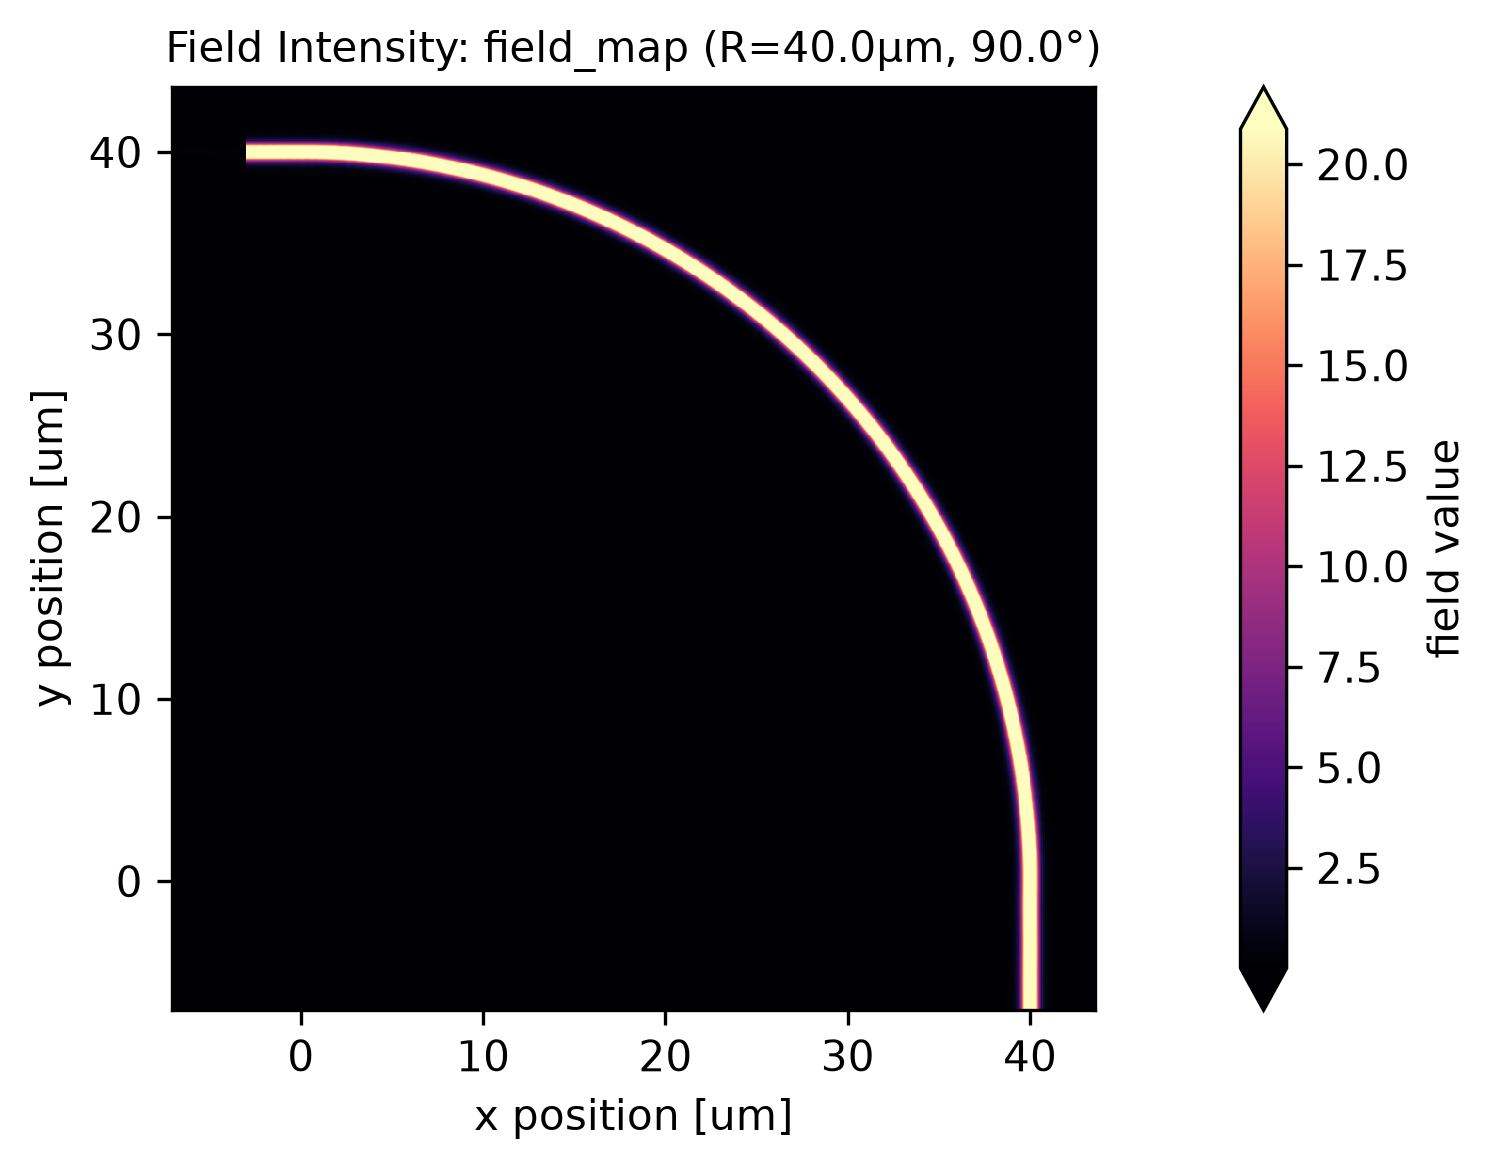

In [14]:
# ---- Test Ring Resonator Arc Analytics ---- #
from pathlib import Path
import tidy3d as td

from geometries import resonator_arc as geom_arc

# Define root output directory for caching and results
out_dir = Path("example_results/ring_resonator/resonator_arcs")

# -- Initialize the Device -- #
example_arc = geom_arc.get_active_simulation(
    wavelength0 = 1.550,
    radius = 40.0,
    wg_width = 0.800,
    wg_height = 0.800,
    core_medium = Si3N4,
    substrate_medium = SiO2,
    bend_angle_deg = 90.0,
    num_absorber_layers = 60,
    fine_steps_per_wvl = 15,
    coarse_steps_per_wvl = 10
)

# -- Run Analytics and Extract Data -- #

efficiency = example_arc.get_efficiency(
    output_dir = out_dir, 
    monitor_name = "Mode Monitor",
    verbose = True
)
print(f"Extracted Efficiency: {efficiency * 100:.2f}%")

loss_db = example_arc.get_loss(
    output_dir = out_dir, 
    monitor_name = "Mode Monitor",
    verbose = False
)
print(f"Extracted Insertion Loss: {loss_db:.2f} dB")

# -- Visualize and Export the Field -- #
example_arc.plot_field(
    output_dir = out_dir,
    monitor_name = "field_map",
    save = True,
    show = True,
    verbose = False
)

## Ring Resonator + Bus Waveguide: Object Methods

/tmp/ipykernel_113230/686748898.py:20: UserWarning: The supplied partial-ring geometry ends inside the simulation domain. Check ring-port reflections and span convergence; its endpoints are not matched absorbers.
  example_ring = geom_partial.get_active_simulation(


--- Analytical Cavity Physics ---


2026-09-21 00:58:12,282 - tarang.ringResonator.ring_resonator - INFO - [Profiler] Cache miss. Uploading partialRingResonator_R40.00um_gap200nm_1.550um_680a6d8c to Tidy3D cloud infrastructure...


Group Index (n_g): 2.2334
Free Spectral Range: 4.280 nm (534.10 GHz)

--- Analyzing Full Ring (Gap = 200 nm) ---


2026-09-21 00:58:49,732 - tarang.ringResonator.ring_resonator - INFO - [Profiler] Execution complete. Serializing data to example_results/ring_resonator/full_rings/partialRingResonator_R40.00um_gap200nm_1.550um_680a6d8c/raw_simulation_data.hdf5...
2026-09-21 00:58:49,789 - tarang.ringResonator.ring_resonator - INFO - [Analytics] Extracting flux coefficients across all mode monitors...
2026-09-21 00:58:49,808 - tarang.ringResonator.ring_resonator - INFO - [Profiler] Cache hit. Loading existing simulation data from example_results/ring_resonator/full_rings/partialRingResonator_R40.00um_gap200nm_1.550um_680a6d8c/raw_simulation_data.hdf5...



Extracted Monitor Fluxes:
  > Through_In:
      Efficiency: 91.03%
      Loss:       0.41 dB
  > Through_Out:
      Efficiency: 62.37%
      Loss:       2.05 dB
  > Ring_Out_Left:
      Efficiency: 4.04%
      Loss:       13.94 dB
  > Ring_Mon_270_Bot:
      Efficiency: 0.00%
      Loss:       51.93 dB
  > Ring_Out_Right:
      Efficiency: 36.90%
      Loss:       4.33 dB

--- Generating Field Map ---


2026-09-21 00:58:50,085 - tarang.ringResonator.ring_resonator - INFO - Saved field plot to example_results/ring_resonator/full_rings/partialRingResonator_R40.00um_gap200nm_1.550um_680a6d8c/spatial_field_coupling_field_map.png


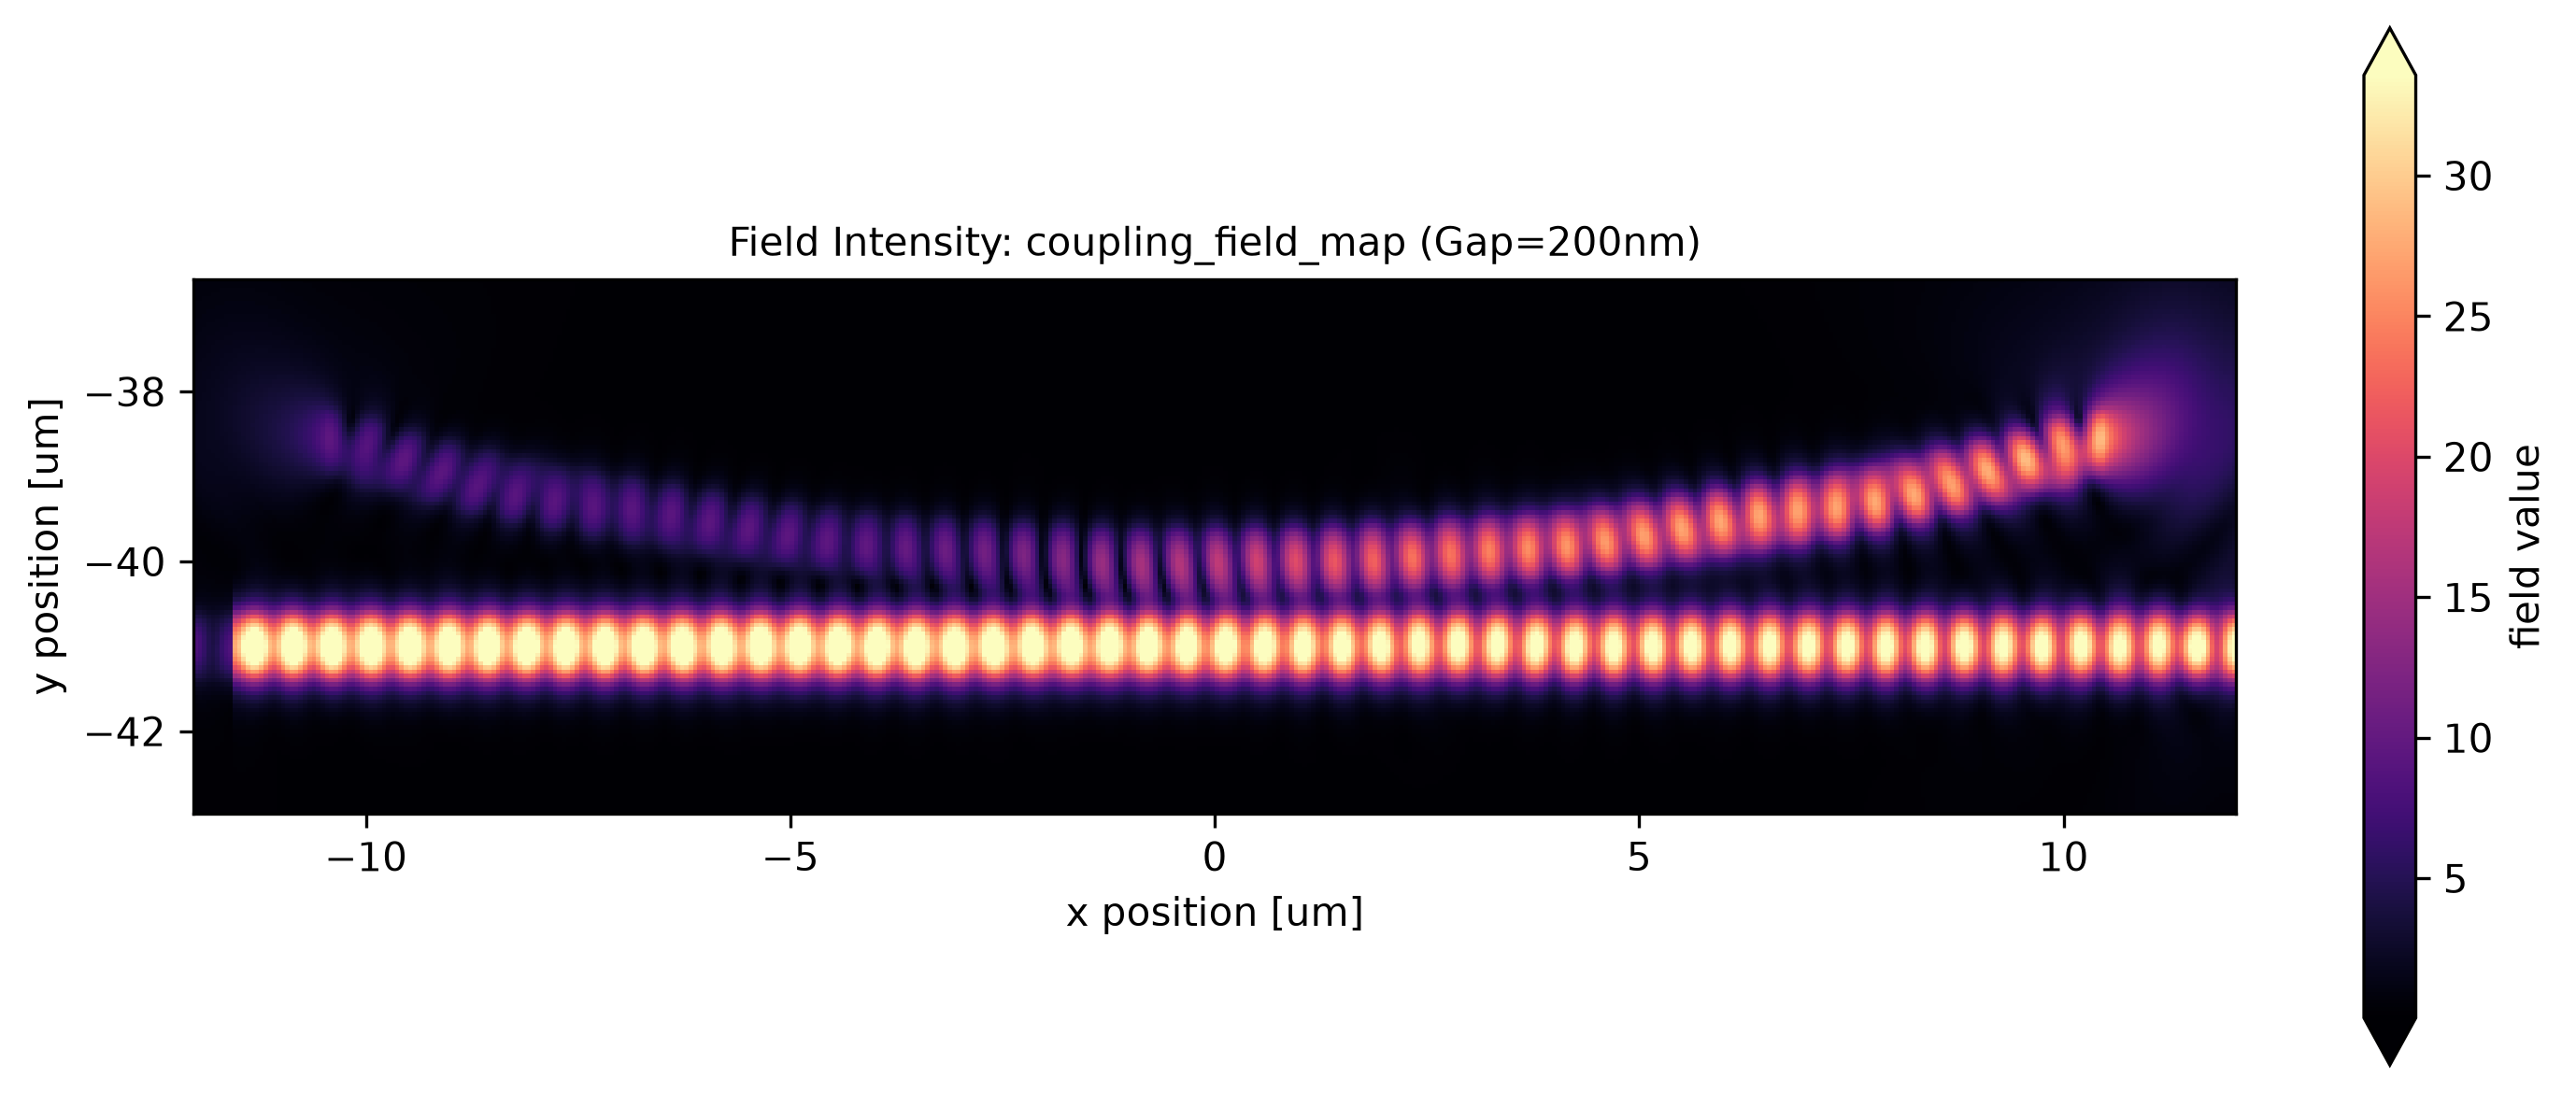

In [15]:
# ---- Test Partial Ring Resonator Physics & Analytics ---- #
from pathlib import Path
import tidy3d as td
import numpy as np

import logging

from geometries import partial_ring_resonator as geom_partial

from tarang import set_tidy3d_log_level

# For a cleaner run (works on Tidy3D 2.12+, where td.config.logging_level was removed)
set_tidy3d_log_level("ERROR")
logging.getLogger("tidy3d").setLevel(logging.ERROR)
logging.getLogger("tidy3d.web").setLevel(logging.ERROR)

# Define root output directory for caching and results
out_dir = Path("example_results/ring_resonator/full_rings")
out_dir.mkdir(parents=True, exist_ok=True)

# -- Initialize the Device -- #
example_ring = geom_partial.get_active_simulation(
    radius = 40.0,
    gap = 0.200,

    span_angle_rad = np.pi / 6.0,
    
    wg_width = 0.800,
    wg_height = 0.800,

    core_medium = Si3N4,
    substrate_medium = SiO2,

    wavelength0 = 1.550,
    
    fine_steps_per_wvl = 15,
    coarse_steps_per_wvl = 10
)

# -- Test Standalone Physics Solvers (FSR & Group Index) -- #
print("--- Analytical Cavity Physics ---")
fsr_nm = example_ring.get_fsr_nm(target_neff=2.0, mode_index=0)
fsr_ghz = example_ring.get_fsr_ghz(target_neff=2.0, mode_index=0)
n_g = example_ring.get_group_index(target_neff=2.0, mode_index=0)

print(f"Group Index (n_g): {n_g:.4f}")
print(f"Free Spectral Range: {fsr_nm:.3f} nm ({fsr_ghz:.2f} GHz)\n")


# -- Run Analytics and Extract Mode Fluxes -- #
# Expect cloud solvers to take over from here
print(f"--- Analyzing Full Ring (Gap = {example_ring.gap * 1000:.0f} nm) ---")

flux_data = example_ring.get_mode_fluxes(
    output_dir = out_dir, 
    verbose = True,
    force_rerun = False
)

# Pretty-print the extracted flux for each monitor in the dictionary
print("\nExtracted Monitor Fluxes:")
for monitor_name, metrics in flux_data.items():
    print(f"  > {monitor_name}:")
    print(f"      Efficiency: {metrics['efficiency_percent']:.2f}%")
    print(f"      Loss:       {metrics['insertion_loss_db']:.2f} dB")

# -- Visualize and Export the Coupling Field -- #
print("\n--- Generating Field Map ---")
example_ring.plot_field(
    output_dir = out_dir,
    monitor_name = "coupling_field_map",
    save = True,
    show = True,
    verbose = False
)

### Ablation Tests: Partial Ring vs Half Ring
Here we demonstrate the differences observed when partial rings of different sizes are simulated.

In [ ]:
# ---- Ring Resonator Span Angle Ablation Test ---- #
import io
import contextlib
import warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tidy3d as td

from tarang import set_tidy3d_output

# Mute Tidy3D logs and progress bars; restore later with set_tidy3d_output(True)
set_tidy3d_output(False)

from geometries import partial_ring_resonator as geom_partial
from geometries import half_ring_resonator as geom_half

out_dir = Path("example_results/ring_resonator/ring_ablation_test")
out_dir.mkdir(parents=True, exist_ok=True)

# Define sweep angles
angles_deg : list  = [30, 45, 75, 90, 180]

# Data containers
results = {
    "angles": [],
    "efficiency_pct": [],
    "loss_db": [],
    "group_index": [],
    "fsr_nm": [],
    "fsr_ghz": []
}

print("=" * 65)
print("     RING RESONATOR SPAN ANGLE ABLATION RUNNER")
print("=" * 65)

for deg in angles_deg:
    print(f"\n[Ablation] Processing Span Angle: {deg}°...")
    rad = np.radians(deg)
    
    # 1. Instantiate Device Architecture
    if deg == 180:
        device = geom_half.get_active_simulation(
            radius=40.0,
            gap=0.200,
            wg_width=0.800,
            wg_height=0.800,
            core_medium=Si3N4,
            substrate_medium=SiO2,
            wavelength0=1.550,
            fine_steps_per_wvl=15,
            coarse_steps_per_wvl=10
        )
    else:
        device = geom_partial.get_active_simulation(
            radius=40.0,
            gap=0.200,
            span_angle_rad=rad,
            wg_width=0.800,
            wg_height=0.800,
            core_medium=Si3N4,
            substrate_medium=SiO2,
            wavelength0=1.550,
            fine_steps_per_wvl=15,
            coarse_steps_per_wvl=10
        )
        
    # 2. Extract Analytical Cavity Physics (2D Mode Solver)
    n_g = device.get_group_index(target_neff=2.0, mode_index=0, local=True)
    fsr_nm = device.get_fsr_nm(target_neff=2.0, mode_index=0, local=True)
    fsr_ghz = device.get_fsr_ghz(target_neff=2.0, mode_index=0, local=True)
    
    # 3. Execute 3D FDTD Simulation & Extract Fluxes
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        flux_data = device.get_mode_fluxes(output_dir=out_dir, verbose=False, force_rerun=False)
    
    thru_metrics = flux_data.get("Through_Out", {})
    eff_pct = thru_metrics.get("efficiency_percent", 0.0)
    loss_db = thru_metrics.get("insertion_loss_db", 0.0)
    
    # Store Metrics
    results["angles"].append(deg)
    results["efficiency_pct"].append(eff_pct)
    results["loss_db"].append(loss_db)
    results["group_index"].append(n_g)
    results["fsr_nm"].append(fsr_nm)
    results["fsr_ghz"].append(fsr_ghz)
    
    print(f"  > Through_Out Efficiency : {eff_pct:.2f}%")
    print(f"  > Through_Out Loss       : {loss_db:.2f} dB")
    print(f"  > Group Index (n_g)      : {n_g:.4f}")
    print(f"  > FSR                    : {fsr_nm:.3f} nm ({fsr_ghz:.2f} GHz)")

# ---- Compute Statistical Summary ---- #
stats = {}
metrics_keys = ["efficiency_pct", "loss_db", "group_index", "fsr_nm", "fsr_ghz"]

for key in metrics_keys:
    data_arr = np.array(results[key])
    stats[key] = {
        "mean": np.mean(data_arr),
        "std": np.std(data_arr),
        "min": np.min(data_arr),
        "max": np.max(data_arr),
        "range": np.ptp(data_arr)
    }

# ---- Comparative Data Table ---- #
print("\n" + "=" * 80)
print(f"{'Span Angle':<12} | {'Through Eff (%)':<17} | {'Loss (dB)':<12} | {'Group Index (ng)':<18} | {'FSR (nm)':<10}")
print("-" * 80)
for i, deg in enumerate(results["angles"]):
    print(f"{deg:<12}° | {results['efficiency_pct'][i]:<17.2f} | {results['loss_db'][i]:<12.2f} | {results['group_index'][i]:<18.4f} | {results['fsr_nm'][i]:<10.3f}")
print("=" * 80)

print("\n" + "=" * 80)
print("                           STATISTICAL SUMMARY")
print("=" * 80)
print(f"{'Metric':<22} | {'Mean':<12} | {'Std Dev (σ)':<14} | {'Range (Max - Min)':<20}")
print("-" * 80)
print(f"{'Through Efficiency (%)':<22} | {stats['efficiency_pct']['mean']:<12.2f} | {stats['efficiency_pct']['std']:<14.2f} | {stats['efficiency_pct']['range']:<20.2f}")
print(f"{'Insertion Loss (dB)':<22} | {stats['loss_db']['mean']:<12.2f} | {stats['loss_db']['std']:<14.2f} | {stats['loss_db']['range']:<20.2f}")
print(f"{'Group Index (n_g)':<22} | {stats['group_index']['mean']:<12.4f} | {stats['group_index']['std']:<14.6f} | {stats['group_index']['range']:<20.6f}")
print(f"{'FSR (nm)':<22} | {stats['fsr_nm']['mean']:<12.3f} | {stats['fsr_nm']['std']:<14.5f} | {stats['fsr_nm']['range']:<20.5f}")
print(f"{'FSR (GHz)':<22} | {stats['fsr_ghz']['mean']:<12.2f} | {stats['fsr_ghz']['std']:<14.4f} | {stats['fsr_ghz']['range']:<20.4f}")
print("=" * 80)

# ---- Render Comparative Plots ---- #
fig, axs = plt.subplots(2, 2, figsize=(12, 8), dpi=300)

# Plot 1: Through Efficiency
axs[0, 0].plot(results["angles"], results["efficiency_pct"], 'o-', color='navy', linewidth=2, markersize=8)
axs[0, 0].set_title("Through-Port Transmission Efficiency", fontweight="bold")
axs[0, 0].set_xlabel("Span Angle (deg)")
axs[0, 0].set_ylabel("Efficiency (%)")
axs[0, 0].grid(True, linestyle="--", alpha=0.6)

# Plot 2: Insertion Loss
axs[0, 1].plot(results["angles"], results["loss_db"], 's-', color='crimson', linewidth=2, markersize=8)
axs[0, 1].set_title("Through-Port Insertion Loss", fontweight="bold")
axs[0, 1].set_xlabel("Span Angle (deg)")
axs[0, 1].set_ylabel("Loss (dB)")
axs[0, 1].grid(True, linestyle="--", alpha=0.6)

# Plot 3: Group Index
axs[1, 0].plot(results["angles"], results["group_index"], '^--', color='darkgreen', linewidth=2, markersize=8)
axs[1, 0].set_title("Group Index ($n_g$)", fontweight="bold")
axs[1, 0].set_xlabel("Span Angle (deg)")
axs[1, 0].set_ylabel("Group Index")
axs[1, 0].grid(True, linestyle="--", alpha=0.6)

# Plot 4: Free Spectral Range (nm)
axs[1, 1].plot(results["angles"], results["fsr_nm"], 'd--', color='purple', linewidth=2, markersize=8)
axs[1, 1].set_title("Free Spectral Range (FSR)", fontweight="bold")
axs[1, 1].set_xlabel("Span Angle (deg)")
axs[1, 1].set_ylabel("FSR (nm)")
axs[1, 1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plot_file = out_dir / "ring_ablation_comparison.png"
plt.savefig(plot_file, bbox_inches="tight")
print(f"\n[Visualizer] Saved comparative ablation plots to: {plot_file}")
plt.show()

     RING RESONATOR SPAN ANGLE ABLATION RUNNER

[Ablation] Processing Span Angle: 30°...


/tmp/ipykernel_113230/2548406917.py:56: UserWarning: The supplied partial-ring geometry ends inside the simulation domain. Check ring-port reflections and span convergence; its endpoints are not matched absorbers.
  device = geom_partial.get_active_simulation(
2026-09-21 00:59:58,622 - tarang.ringResonator.ring_resonator - INFO - [Profiler] Cache miss. Uploading partialRingResonator_R40.00um_gap200nm_1.550um_680a6d8c to Tidy3D cloud infrastructure...
2026-09-21 00:59:58,741 - tarang.ringResonator.ring_resonator - INFO - [Profiler] Execution complete. Serializing data to example_results/ring_resonator/ring_ablation_test/partialRingResonator_R40.00um_gap200nm_1.550um_680a6d8c/raw_simulation_data.hdf5...
2026-09-21 00:59:58,796 - tarang.ringResonator.ring_resonator - INFO - [Analytics] Extracting flux coefficients across all mode monitors...
/tmp/ipykernel_113230/2548406917.py:56: UserWarning: The supplied partial-ring geometry ends inside the simulation domain. Check ring-port reflection

  > Through_Out Efficiency : 62.37%
  > Through_Out Loss       : 2.05 dB
  > Group Index (n_g)      : 2.2321
  > FSR                    : 4.283 nm (534.41 GHz)

[Ablation] Processing Span Angle: 45°...


2026-09-21 01:00:03,795 - tarang.ringResonator.ring_resonator - INFO - [Profiler] Cache miss. Uploading partialRingResonator_R40.00um_gap200nm_1.550um_0faaaea3 to Tidy3D cloud infrastructure...
2026-09-21 01:00:52,001 - tarang.ringResonator.ring_resonator - INFO - [Profiler] Execution complete. Serializing data to example_results/ring_resonator/ring_ablation_test/partialRingResonator_R40.00um_gap200nm_1.550um_0faaaea3/raw_simulation_data.hdf5...
2026-09-21 01:00:52,054 - tarang.ringResonator.ring_resonator - INFO - [Analytics] Extracting flux coefficients across all mode monitors...
/tmp/ipykernel_113230/2548406917.py:56: UserWarning: The supplied partial-ring geometry ends inside the simulation domain. Check ring-port reflections and span convergence; its endpoints are not matched absorbers.
  device = geom_partial.get_active_simulation(


  > Through_Out Efficiency : 64.83%
  > Through_Out Loss       : 1.88 dB
  > Group Index (n_g)      : 2.2321
  > FSR                    : 4.283 nm (534.41 GHz)

[Ablation] Processing Span Angle: 75°...


2026-09-21 01:00:56,563 - tarang.ringResonator.ring_resonator - INFO - [Profiler] Cache miss. Uploading partialRingResonator_R40.00um_gap200nm_1.550um_08c8cdba to Tidy3D cloud infrastructure...
2026-09-21 01:01:51,507 - tarang.ringResonator.ring_resonator - INFO - [Profiler] Execution complete. Serializing data to example_results/ring_resonator/ring_ablation_test/partialRingResonator_R40.00um_gap200nm_1.550um_08c8cdba/raw_simulation_data.hdf5...
2026-09-21 01:01:51,624 - tarang.ringResonator.ring_resonator - INFO - [Analytics] Extracting flux coefficients across all mode monitors...
/tmp/ipykernel_113230/2548406917.py:56: UserWarning: The supplied partial-ring geometry ends inside the simulation domain. Check ring-port reflections and span convergence; its endpoints are not matched absorbers.
  device = geom_partial.get_active_simulation(


  > Through_Out Efficiency : 65.06%
  > Through_Out Loss       : 1.87 dB
  > Group Index (n_g)      : 2.2321
  > FSR                    : 4.283 nm (534.41 GHz)

[Ablation] Processing Span Angle: 90°...


2026-09-21 01:01:56,139 - tarang.ringResonator.ring_resonator - INFO - [Profiler] Cache miss. Uploading partialRingResonator_R40.00um_gap200nm_1.550um_bbac8660 to Tidy3D cloud infrastructure...


## Sweep Functions: Ring Radius Sweep, and Ring + Waveguide Gap Sweep

In [17]:
wavelength_um = 1.550
wg_width = 0.800
wg_height = 0.800

# -- Define Media -- #
# We do this again
from media import get_medium

Si3N4 = get_medium(
    medium_key = "si3n4",
    wl_range = (1.550 - 0.200, 1.550 + 0.200),
    tolerance = 1e-5
)

SiO2 = get_medium(
    medium_key = "sio2",
    wl_range = (1.550 - 0.200, 1.550 + 0.200),
    tolerance = 5e-5
)

Air = get_medium(
    medium_key="air",
    wl_range=(1.350, 1.750),
)

2026-09-21 01:06:33,854 - tarang.media.medium_helper - INFO -  Cache HIT for si3n4. Reusing Luke_Si3N4_e9174844.json (Fit range: [1.35, 1.75], RMS: 2.66e-15, Poles allowed: 10).
2026-09-21 01:06:33,859 - tarang.media.medium_helper - INFO -  Cache HIT for sio2. Reusing Nyakuchena_fusedSilica_65d24012.json (Fit range: [1.35, 1.75], RMS: 1.32e-05, Poles allowed: 10).
2026-09-21 01:06:33,861 - tarang.media.medium_helper - INFO -  Bypassing file system for air. Returning dispersionless vacuum medium (n=1.0)...


In [ ]:
# ---- Analytical Ring Radius Sweep: Inputs and Execution ---- #
"""Evaluate radius-dependent cavity metrics using supplied loss and group index.

Run the preceding sweep setup cell first (materials, wavelength, and dimensions).
These two cells do not require the earlier FDTD examples to be executed.
No FDTD or mode solver is called: n_group must be supplied explicitly.
None means missing data, never zero loss or an assumed refractive index.
"""
from pathlib import Path
from ringResonator.ring_radius_sweep import radius_sweep_analytical

# Illustrative design grid in um
radii_um = [20.0, 30.0, 40.0, 60.0, 80.0, 100.0]
radius_output_dir = Path("example_results/ring_resonator/analytical_radius_sweep")

# REQUIRED: total POWER propagation loss in dB/cm at each radius, INCLUDING
# scattering, absorption, and bend radiation. Match wavelength, cross section,
# polarization, cladding, and fabrication process to the setup cell above.
# Do not substitute a bus-to-ring insertion loss or a loaded-Q measurement.
total_loss_db_cm = {radius: None for radius in radii_um}

# REQUIRED by the API: nonnegative scattering component in dB/cm, assumed
# constant over this radius grid and already included in every total above.
# Do not add it again. Zero is valid only if justified by your model/data.
scattering_loss_db_cm = None

# REQUIRED for this purely analytical example: positive modal GROUP index,
# not bulk refractive index or phase effective index. A shared scalar is also
# accepted by the API if radius independence is justified; mappings retain
# possible bend dependence. Never pass None through to the API (solver fallback).
n_group = {radius: None for radius in radii_um}

# Fill in references/measurement provenance alongside the values you find.
# References are recorded separately from the library's physics manifest.
radius_input_sources = {
    "total_loss_db_cm": "",  # REQUIRED provenance: paper/DOI or measurement details.
    "scattering_loss_db_cm": "",  # REQUIRED provenance for the loss decomposition.
    "n_group": "",  # REQUIRED provenance: measured or independently validated value.
}

# Optional full-ring effective optical mode volumes (um^3), keyed by radius.
# Leaving this None uses V = 2*pi*R*wg_width*wg_height, a GEOMETRIC core-volume
# proxy, not an experimentally established effective mode volume.
volume_um3_by_radius = None
radius_input_sources["effective_mode_volume"] = ""  # Needed only if supplied.

# Clear old results before checking inputs, so rerunning with blanks cannot
# accidentally display a previous sweep as the current result.
radius_results = None
radius_summary = None
missing_inputs = []
for name, values in (("total_loss_db_cm", total_loss_db_cm), ("n_group", n_group)):
    if values is None:
        missing_inputs.append(name)
    elif isinstance(values, dict):
        for radius in radii_um:
            if values.get(radius, values.get(str(radius))) is None:
                missing_inputs.append(f"{name}[{radius} um]")
if scattering_loss_db_cm is None:
    missing_inputs.append("scattering_loss_db_cm")

if missing_inputs:
    print("Sweep not run. Supply the following measured or cited/model inputs:")
    print("\n".join(f"  - {name}" for name in missing_inputs))
else:
    radius_results = radius_sweep_analytical(
        radii_sweep_list=radii_um,
        output_dir=radius_output_dir,
        core_medium=Si3N4,
        substrate_medium=SiO2,
        cladding_medium=Air,
        wg_width=wg_width,
        wg_height=wg_height,
        wavelength_um=wavelength_um,
        total_loss_db_cm=total_loss_db_cm,
        scattering_loss_db_cm=scattering_loss_db_cm,
        n_group=n_group,
        volume_um3_by_radius=volume_um3_by_radius,
        volume_label=("supplied effective mode volume" if volume_um3_by_radius is not None
                      else "geometric core volume (proxy)"),
        save_plots=False,  # The second cell saves/displays the summary figure.
        show_plots=False,
        plot_dpi=150,
    )
    import json
    (radius_output_dir / "input_sources.json").write_text(
        json.dumps(radius_input_sources, indent=2), encoding="utf-8"
    )
    print(f"Analytical sweep complete: {len(radius_results)} radii; {radius_output_dir}")


In [ ]:
# ---- Analytical Radius Sweep: Inspect and Plot Results ---- #
"""Display the preceding sweep's metrics without solving or running simulations.

Tarang computes intrinsic Q from supplied total attenuation and modal group
index, and FSR from the full circumference. Its FOM is (Q_intrinsic/2)^2 / V,
assuming critical coupling. This does not determine the required bus-ring gap
or verify loaded Q. With geometric V, interpret the FOM as a comparison proxy.
Constant loss and group index make Q constant and FSR/FOM scale as 1/R;
that alone does not establish the smallest ring as a physical optimum.

The API labels total minus scattering as bend_loss_db_cm. If the supplied
loss also contains absorption or other mechanisms, that remainder is NOT an
isolated bend-loss measurement. Zero total loss represents infinite Q (stored
as None plus a flag), not a finite predicted quality factor.
"""
import pandas as pd
from IPython.display import display
from ringResonator.ring_radius_sweep import plot_radius_summary

if not globals().get("radius_results"):
    print("No current analytical results. Fill the required inputs and run the preceding cell.")
else:
    radius_table = pd.DataFrame(radius_results.values()).sort_values("radius_um")
    display(radius_table[[
        "radius_um", "total_loss_db_cm", "n_group", "q_intrinsic",
        "q_intrinsic_is_infinite", "fsr_nm", "fsr_ghz", "volume_um3",
        "fom_at_critical",
    ]].reset_index(drop=True))

    radius_summary = plot_radius_summary(
        radius_results,
        output_dir=radius_output_dir,
        save=True,
        show=True,
        annotate=True,
        plot_dpi=150,
    )
    print(f"Summary figure: {radius_summary['figure_path']}")
    print(f"Physics report: {radius_output_dir / 'intrinsic_physics_manifest.json'}")
    print("Summary data: radius_fom_fsr_datapoints.json; provenance: input_sources.json")
    print(radius_summary["fom_assumption"])
    print(radius_summary["selection_note"])
